# Étude Cofitypotel : profils de conseillers et score de bon vendeur

*Thibault Perz et David Doe, encadrés par David Sestu (Master SIAD, Université de Lille)*

Ce notebook refait en Python toute l'étude, des données brutes jusqu'au croisement final, et prépare les tables du tableau de bord Power BI. Chaque partie suit le même fil : la question, la méthode, le code, puis ce que montrent les résultats.

> **Données.** Le fichier du cours (`Donnees_Cofitypotel.xls`) est dans le dossier `donnees/`. Les codes des conseillers sont remplacés par des numéros dès la lecture.
>
> **Écarts avec les rapports rédigés.** Tous les chiffres commentés ici sortent de ce notebook. Ils diffèrent parfois des deux rapports d'origine : le temps de retrait est désormais converti sans être tronqué à 24 h, et la répartition en groupes est alignée sur la typologie de la mission 1. Le README résume ces écarts.

**Sommaire**

1. Synthèse du projet
2. Contexte et objectifs
3. Données et préparation
4. Mission 1 : typologie comportementale
5. Mission 1 : validation et modèle d'affectation (analyse discriminante)
6. Mission 1 : migrations entre trimestres
7. Mission 2 : performance commerciale par groupe
8. Mission 2 : modèle de score « bon vendeur » (régression logistique)
9. Mission 2 : croisement score × groupes, et tables pour Power BI
10. Préconisations
11. Limites et perspectives
12. Annexes

---
# 1. Synthèse du projet

## 1.1 En une page

| | |
|---|---|
| **Client** | Cofitypotel, société de crédit à la consommation qui vend par téléphone : crédit revolving (*Formule Libravou*), crédits amortissables, assurances, augmentations de réserves. |
| **Question** | Les conseillers ont-ils des façons de travailler au téléphone différentes et stables ? Ces façons de travailler expliquent-elles les ventes ? |
| **Données** | Fichier mensuel de téléphonie et de ventes, janvier 2003 à décembre 2004, 73 variables. Après préparation : 907 observations conseiller × trimestre, 251 conseillers, 8 trimestres. |
| **Mission 1** | Typologie sur les seules données de téléphonie (4 groupes), validation par analyse discriminante, modèle d'affectation, migrations d'un trimestre à l'autre. |
| **Mission 2** | Score de « bon vendeur » en augmentations de réserves par régression logistique, puis croisement avec les groupes. |
| **Résultat principal** | Le score repère bien les bons vendeurs : AUC de 0,818 sur l'échantillon test. Traiter beaucoup d'appels entrants et passer son temps disponible en conversation vont avec de bonnes ventes ; une forte part d'appels sortants va avec de moins bonnes ventes. Les deux analyses, menées séparément, désignent les mêmes groupes : les **actifs qualitatifs** vendent le mieux (70 % de bons vendeurs), les **spécialistes sortants** le moins bien (17 %). |

## 1.2 Démarche d'ensemble

| Étape | Méthodes | Sortie |
|---|---|---|
| 0. Préparation | Agrégation trimestrielle, normalisation à 7 h par jour, winsorisation 1-99 % | 907 observations, 13 indicateurs |
| 1. Typologie | Statistiques descriptives, ACP, CAH (Ward) puis K-means, indices base 100 | 4 groupes |
| 2. Validation et affectation | Analyse discriminante linéaire, validation croisée Leave-One-Out | Fonction `predire_groupe()` |
| 3. Migrations | Matrice de transition entre trimestres | Stabilité par groupe |
| 4. Performance par groupe | Kruskal-Wallis, test de Dunn (Bonferroni) | Comparaison des ventes |
| 5. Score « bon vendeur » | Mann-Whitney, V de Cramér, Spearman, VIF, régression logistique, ROC, lift | Modèle à 4 variables |
| 6. Croisement | Taux de bons vendeurs et score moyen par groupe | Test de cohérence |
| 7. Restitution | Export CSV, tableau de bord Power BI | `sorties/`, `powerbi/` |

---
# 2. Contexte et objectifs

## 2.1 La plateforme

Les conseillers vendent par téléphone une gamme de produits de crédit. Les objectifs commerciaux sont **uniformes**, mais chacun garde une grande latitude dans son organisation : volume d'appels, stratégie de relance, temps consacré à chaque client. Deux catégories de conseillers coexistent :

| Métier | Observations (conseiller × trimestre) | Rôle | Produits autorisés |
|---|---|---|---|
| HML | 450 | Habilités au montage de crédit en ligne : réalisent des études de crédit en direct avec le client | FL, AMO, assurance + études en ligne |
| NHML | 457 | Non habilités : envoient un contrat vierge par courrier | FL, AMO, assurance (contrats vierges uniquement) |

Cette distinction est structurante : les HML consacrent une part de leur temps aux études en ligne, ce qui **réduit mécaniquement leur volume d'appels** par rapport aux NHML.

## 2.2 Trois remarques préalables du responsable

1. **Les comportements varient dans le temps** → il faut un niveau d'agrégation temporelle assez large pour obtenir une image stable.
2. **Le temps de présence est très hétérogène et exogène** (absences, formations, réunions, temps partiel) → les indicateurs sont comparés à temps de présence équivalent (normalisation à 7 h/jour).
3. **Les ventes ne se concrétisent jamais au moment de l'appel** (le client reçoit, lit, signe et retourne son contrat) → agrégation **au trimestre**, fenêtre sur laquelle les effets de délai se compensent.

## 2.3 Objectifs

* **Mission 1.** Établir une typologie comportementale **sur la base exclusive des données de téléphonie, indépendamment de la performance commerciale** ; élaborer un modèle d'affectation d'un nouveau conseiller à un groupe ; analyser les migrations entre groupes au fil des trimestres.
* **Mission 2.** Comparer les performances des groupes, puis expliquer par régression logistique la variable « être bon vendeur en **augmentations de réserves** » (proposer à un client Libravou d'augmenter son plafond de crédit revolving : un produit fondé sur une relation client préexistante), enfin relier le modèle aux typologies.

> **Choix méthodologique central.** Construire les groupes sans aucune donnée de vente garantit qu'ils reflètent des différences de *pratiques* et non de *performance*. On peut ensuite tester, de façon honnête, si ces groupes diffèrent par leurs résultats.

---
# 3. Données et préparation

## 3.0 Environnement et configuration

Dépendances : `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn` (+ `xlrd` pour lire un fichier `.xls`). La régression logistique est implémentée directement (algorithme IRLS, § 8) afin de ne dépendre que de ces bibliothèques ; elle reproduit exactement `glm(family = binomial)` de R.

In [1]:
import datetime as dt
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.special import expit
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score, roc_curve, silhouette_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

try:
    from IPython.display import display
except ImportError:          # exécution hors Jupyter
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)

# --- Données : le fichier du cours n'est pas publié. Il faut le placer dans donnees/.
DOSSIER_DONNEES = Path("../donnees")
FICHIER = next((p for p in (DOSSIER_DONNEES / "Donnees_Cofitypotel.xls",
                            DOSSIER_DONNEES / "Donnees_Cofitypotel.xlsx",
                            DOSSIER_DONNEES / "Donnees_Cofitypotel_Feuil1.csv") if p.exists()), None)
if FICHIER is None:
    raise FileNotFoundError("Placez Donnees_Cofitypotel.xls dans le dossier donnees/ (voir le README).")
DOSSIER_SORTIES = Path("../sorties")
DOSSIER_FIGURES = Path("../figures")
DOSSIER_SORTIES.mkdir(exist_ok=True)
DOSSIER_FIGURES.mkdir(exist_ok=True)

# --- Habillage commun
PALETTE = {1: "#9B59B6", 2: "#2E86AB", 3: "#F4A261", 4: "#57CC99"}
NOMS_GROUPES = {1: "G1 — Relanceurs intensifs", 2: "G2 — Actifs qualitatifs",
                3: "G3 — Spécialistes sortants", 4: "G4 — Actifs standard"}
COULEURS_METIER = {"HML": "#2E86AB", "NHML": "#E84855"}
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#E84855", "#FFFFFF", "#2E86AB"])


def tab(df, cap=None, index=False, precision=3):
    """Affiche un tableau mis en forme (équivalent de kable + kableExtra)."""
    sty = df.style.format(precision=precision)
    if cap:
        sty = sty.set_caption(cap)
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.set_table_styles([
        {"selector": "caption", "props": [("font-weight", "bold"), ("text-align", "left"), ("padding", "6px 0")]},
        {"selector": "th", "props": [("background-color", "#f2f4f7"), ("font-size", "12px")]},
        {"selector": "td", "props": [("font-size", "12px")]},
    ])
    display(sty)


def montre(nom=None):
    """Termine une figure, et l'enregistre dans figures/ si un nom est donné."""
    plt.tight_layout()
    if nom:
        plt.savefig(DOSSIER_FIGURES / f"{nom}.png", dpi=150, bbox_inches="tight")
    plt.show()


def ellipse(ax, pts, couleur, niveau=0.90, de_la_moyenne=False, remplie=True):
    """Ellipse de dispersion (normale) ou de confiance de la moyenne autour d'un nuage de points 2D."""
    pts = np.asarray(pts)
    cov = np.cov(pts.T)
    if de_la_moyenne:
        cov = cov / len(pts)
    vals, vecs = np.linalg.eigh(cov)
    ordre = vals.argsort()[::-1]
    vals, vecs = vals[ordre], vecs[:, ordre]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    k = np.sqrt(stats.chi2.ppf(niveau, 2))
    centre = pts.mean(axis=0)
    ax.add_patch(Ellipse(centre, 2 * k * np.sqrt(vals[0]), 2 * k * np.sqrt(vals[1]), angle=angle,
                         facecolor=couleur if remplie else "none", edgecolor=couleur,
                         alpha=0.15 if remplie else 1, lw=1.5))
    if remplie:
        ax.add_patch(Ellipse(centre, 2 * k * np.sqrt(vals[0]), 2 * k * np.sqrt(vals[1]), angle=angle,
                             facecolor="none", edgecolor=couleur, lw=1.5))


print(f"Données : {FICHIER.name}")

Données : Donnees_Cofitypotel_Feuil1.csv


## 3.1 Lecture et filtrage

La base brute compte 2 502 observations mensuelles. Le code métier `COURRIER` (une seule occurrence, toutes valeurs à 0) est exclu : seuls les conseillers `HML` et `NHML` sont conservés.

In [2]:
if FICHIER.suffix == ".csv":
    df_raw = pd.read_csv(FICHIER, sep=";", skiprows=5, low_memory=False)
else:
    df_raw = pd.read_excel(FICHIER, sheet_name="Feuil1", skiprows=5)
df_raw.columns = [str(c).strip() for c in df_raw.columns]   # « code OP » a une espace en trop dans le fichier

df_raw = df_raw[df_raw["code OP"].notna() & df_raw["métier 2"].isin(["HML", "NHML"])].copy()

# Les codes des conseillers sont remplacés par des numéros (C001, C002…) : aucun identifiant réel ne sort du notebook
codes = sorted(df_raw["code OP"].astype(str).str.strip().unique())
df_raw["code OP"] = df_raw["code OP"].astype(str).str.strip().map({c: f"C{i + 1:03d}" for i, c in enumerate(codes)})

print("Dimensions brutes    :", df_raw.shape[0], "lignes x", df_raw.shape[1], "colonnes")
print("Conseillers distincts:", df_raw["code OP"].astype(str).str.strip().nunique())
print("Périodes             :", df_raw["Période"].nunique())

Dimensions brutes    : 2501 lignes x 73 colonnes
Conseillers distincts: 260
Périodes             : 24


## 3.2 Sélection et conversion des variables de téléphonie

Le temps de retrait est stocké au format durée d'Excel, en fraction de jour : 0,5 vaut 12 heures. **Correction par rapport à la version R d'origine** : celle-ci ne gardait que l'heure du jour (équivalent de `%% 86400`), ce qui tronquait toutes les durées mensuelles au-delà de 24 h, soit environ un quart des lignes. Ici, la durée complète est convertie en minutes.

Le nombre de jours de présence mensuel est calculé à partir de l'ETP et du nombre de semaines ; lorsque l'ETP est nul, il est **estimé via le temps de disponibilité** (`dispo / 420 min`) pour ne pas perdre ces observations.

In [3]:
def en_minutes(v):
    """Durée Excel (fraction de jour, timedelta, heure ou date) -> minutes, sans tronquer à 24 h."""
    if v is None or (not isinstance(v, (dt.time, dt.timedelta)) and pd.isna(v)):
        return np.nan
    if isinstance(v, dt.time):
        return v.hour * 60 + v.minute + v.second / 60
    if isinstance(v, (pd.Timestamp, dt.datetime)):           # xlrd lit les durées > 24 h comme des dates de 1900
        return (v - pd.Timestamp("1899-12-30")).total_seconds() / 60
    if isinstance(v, (pd.Timedelta, dt.timedelta)):
        return v.total_seconds() / 60
    try:
        return float(v) * 1440
    except (TypeError, ValueError):
        return np.nan


def num(col):
    return pd.to_numeric(df_raw[col], errors="coerce")


df_tel = pd.DataFrame({
    "trimestre":         df_raw["trimestre"].astype(str).str.strip(),
    "code_op":           df_raw["code OP"].astype(str).str.strip(),
    "metier":            df_raw["métier 2"].astype(str),
    "nb_semaines":       num("Nombre de semaines"),
    "etp":               num("Equivalent temps plein (obj)"),
    "appels_presentes":  num("Appels présentés"),
    "appels_pris":       num("Appels pris"),
    "dispo_min":         num("temps total de disponibilité en minutes"),
    "conv_entrants_min": num("temps total de conversation sur appels entrants en minutes"),
    "appels_sortants":   num("nb appels sortants"),
    "conv_sortants_min": num("temps total conversation sur appels sortants en minutes"),
    "retrait_min":       df_raw["temps total de retrait"].map(en_minutes),
})
df_tel["nb_jours_mois"] = np.where(df_tel["etp"] > 0,
                                   df_tel["nb_semaines"] * 5 * df_tel["etp"],
                                   df_tel["dispo_min"] / 420)

print("Base téléphonique :", len(df_tel), "observations mensuelles")
print("ETP = 0           :", int((df_tel["etp"] == 0).sum()), "cas (estimation via dispo)")

Base téléphonique : 2501 observations mensuelles
ETP = 0           : 559 cas (estimation via dispo)


## 3.3 Agrégation au trimestre

In [4]:
vars_volume = ["appels_presentes", "appels_pris", "dispo_min", "conv_entrants_min",
               "appels_sortants", "conv_sortants_min", "retrait_min", "nb_jours_mois"]

df_trim = (df_tel.groupby(["code_op", "trimestre"], as_index=False)
           .agg(metier=("metier", "first"), nb_mois=("metier", "size"),
                **{v: (v, "sum") for v in vars_volume})
           .rename(columns={"nb_jours_mois": "nb_jours_trim"}))

# Activité minimale : au moins 1 jour de présence, 1 appel pris et une disponibilité non nulle
# (écarte les observations qui produiraient des divisions par zéro dans les ratios)
n_avant = len(df_trim)
df_trim = df_trim[(df_trim["nb_jours_trim"] >= 1) & (df_trim["appels_pris"] > 0)
                  & (df_trim["dispo_min"] > 0)].reset_index(drop=True)

print("Base trimestrielle:", len(df_trim), "observations |",
      df_trim["code_op"].nunique(), "conseillers |", df_trim["trimestre"].nunique(), "trimestres",
      f"({n_avant - len(df_trim)} observation(s) écartée(s) pour activité nulle)")

Base trimestrielle: 907 observations | 251 conseillers | 8 trimestres (42 observation(s) écartée(s) pour activité nulle)


## 3.4 Normalisation à 7 h/jour et construction des 13 indicateurs

Les **volumes** sont rapportés au nombre de jours de présence du trimestre (équivalent d'un conseiller à temps plein). Mais la normalisation mesure l'*intensité* de l'activité, pas la *manière* dont elle est conduite : cinq **ratios**, calculés sur les totaux trimestriels, comblent ce manque.

| Variable | Type | Formule / sens |
|---|---|---|
| Appels présentés/j | Volume | Appels entrants reçus par jour |
| Appels pris/j | Volume | Appels décrochés par jour |
| Disponibilité/j (min) | Volume | Temps de disponibilité téléphonique |
| Conv. entrants/j (min) | Volume | Temps de conversation entrant |
| Appels sortants/j | Volume | Appels émis par jour |
| Conv. sortants/j (min) | Volume | Temps de conversation sortant |
| Conv. totale/j (min) | Volume | Conv. entrants + sortants |
| Retrait/j (min) | Volume | Temps de mise en attente (retrait) |
| TMC entrants (min) | Ratio | Conv. entrants / appels pris — profondeur de la relation client |
| Appels pris/heure | Ratio | Appels pris / (dispo en min / 60) — productivité horaire |
| Taux décroché | Ratio | Appels pris / appels présentés — réactivité |
| Part conv./dispo | Ratio | (Conv. ent. + sort.) / dispo — taux d'occupation |
| Part sortant/conv | Ratio | Conv. sortants / conv. totale — orientation stratégique |

In [5]:
j = df_trim["nb_jours_trim"]
conv_tot = df_trim["conv_entrants_min"] + df_trim["conv_sortants_min"]

df_trim = df_trim.assign(
    # Volumes par jour de présence
    appels_presentes_j  = df_trim["appels_presentes"]  / j,
    appels_pris_j       = df_trim["appels_pris"]       / j,
    dispo_min_j         = df_trim["dispo_min"]         / j,
    conv_entrants_min_j = df_trim["conv_entrants_min"] / j,
    appels_sortants_j   = df_trim["appels_sortants"]   / j,
    conv_sortants_min_j = df_trim["conv_sortants_min"] / j,
    conv_totale_j       = conv_tot                     / j,
    retrait_min_j       = df_trim["retrait_min"]       / j,
    # Ratios (calculés sur les totaux trimestriels, plus précis)
    tmc_entrants        = df_trim["conv_entrants_min"] / df_trim["appels_pris"],
    appels_pris_h       = df_trim["appels_pris"] / (df_trim["dispo_min"] / 60),
    taux_decroche       = df_trim["appels_pris"] / df_trim["appels_presentes"],
    part_conv_dispo     = conv_tot / df_trim["dispo_min"],
    part_sortant_conv   = np.where(conv_tot > 0, df_trim["conv_sortants_min"] / conv_tot.where(conv_tot > 0), 0.0),
)

VARS_ANALYSE = ["appels_presentes_j", "appels_pris_j", "dispo_min_j", "conv_entrants_min_j",
                "appels_sortants_j", "conv_sortants_min_j", "conv_totale_j", "retrait_min_j",
                "tmc_entrants", "appels_pris_h", "taux_decroche", "part_conv_dispo",
                "part_sortant_conv"]
LABELS_VARS = ["Appels prés/j", "Appels pris/j", "Dispo/j", "Conv ent/j", "App sort/j",
               "Conv sort/j", "Conv tot/j", "Retrait/j", "TMC ent", "App pris/h",
               "Tx décroché", "Part conv/dispo", "Part sort/conv"]

## 3.5 Valeurs extrêmes : winsorisation 1 %-99 %

Le tableau descriptif de la partie 4 compte, pour chaque indicateur, les valeurs hors de la règle de l'écart interquartile. Les supprimer coûterait trop d'observations, et beaucoup viennent de la normalisation par le temps de présence. On les **winsorise** : les valeurs sous le 1er percentile ou au-dessus du 99e sont ramenées à ces bornes. Les observations gardent leur rang et l'échantillon garde sa taille.

In [6]:
def winsorise(s, p_bas=0.01, p_haut=0.99):
    return s.clip(lower=s.quantile(p_bas), upper=s.quantile(p_haut))


for v in VARS_ANALYSE:
    df_trim[v + "_w"] = winsorise(df_trim[v])
VARS_W = [v + "_w" for v in VARS_ANALYSE]

print("Valeurs manquantes sur les 13 indicateurs :", int(df_trim[VARS_W].isna().sum().sum()))

Valeurs manquantes sur les 13 indicateurs : 0


**Bilan de la préparation.** Après exclusion du code métier `COURRIER`, agrégation au trimestre et filtre d'activité minimale (au moins un jour de présence, un appel pris et une disponibilité non nulle, ce qui écarte 42 couples conseiller × trimestre sans activité téléphonique réelle), la base compte **907 observations**, **251 conseillers** et **8 trimestres**, sans valeur manquante.

---
# 4. Mission 1 — Typologie comportementale

## 4.1 Analyse univariée

### Statistiques descriptives

In [7]:
def stats_desc(x, nom):
    x = x.dropna()
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3 - q1
    return {"Variable": nom, "N": len(x), "Moyenne": x.mean(), "Médiane": x.median(),
            "Éc. type": x.std(), "Min": x.min(), "Q1": q1, "Q3": q3, "Max": x.max(),
            "Asymétrie": stats.skew(x), "Kurtosis": stats.kurtosis(x, fisher=False),
            "Nb outliers": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())}


table_stats = pd.DataFrame([stats_desc(df_trim[v], l) for v, l in zip(VARS_ANALYSE, LABELS_VARS)])
tab(table_stats, "Statistiques descriptives — variables normalisées (avant winsorisation)")

Variable,N,Moyenne,Médiane,Éc. type,Min,Q1,Q3,Max,Asymétrie,Kurtosis,Nb outliers
Appels prés/j,907,105.981,103.914,28.382,2.220,87.807,121.123,223.827,0.296,4.283,33
Appels pris/j,907,99.058,96.954,27.128,2.035,81.492,113.752,216.238,0.238,4.315,32
Dispo/j,907,317.525,310.896,67.333,8.986,274.376,360.663,429.264,-0.130,3.084,5
Conv ent/j,907,218.592,215.249,71.688,6.547,171.781,260.811,505.445,0.166,3.403,26
App sort/j,907,19.116,15.803,16.147,0.556,11.267,23.718,309.881,8.681,134.248,34
Conv sort/j,907,33.445,19.975,48.437,1.157,13.837,28.899,845.518,7.689,103.400,134
Conv tot/j,907,252.037,242.501,74.383,9.655,210.006,283.773,1213.717,3.384,38.609,33
Retrait/j,907,87.865,57.189,219.677,8.197,42.275,81.863,5032.042,15.760,312.252,73
TMC ent,907,2.255,2.201,0.629,0.048,1.857,2.560,6.168,0.785,5.971,33
App pris/h,907,18.928,18.848,3.870,0.291,16.532,21.330,32.461,-0.590,6.085,20


### Distributions

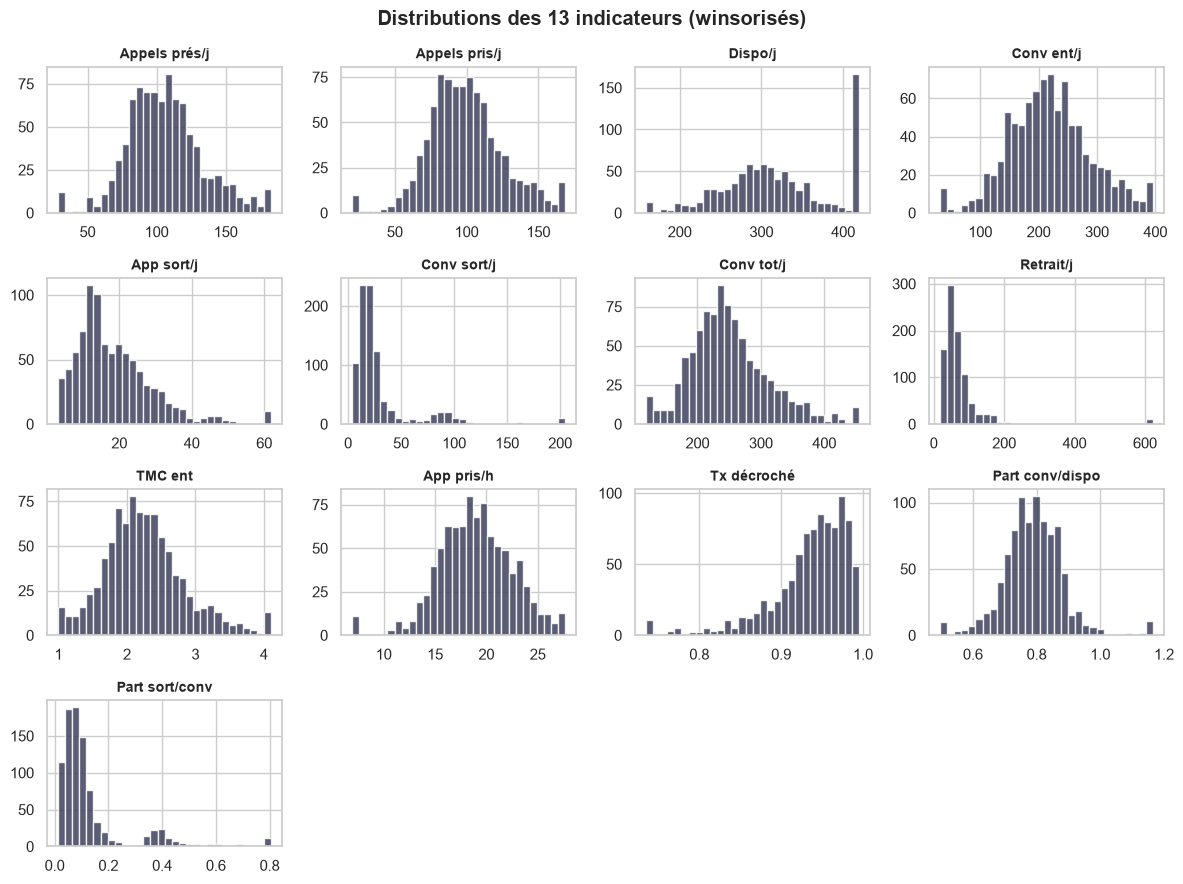

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(12, 9))
for ax, v, l in zip(axes.ravel(), VARS_W, LABELS_VARS):
    ax.hist(df_trim[v], bins=30, color="#3D405B", edgecolor="white", alpha=.85)
    ax.set_title(l, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(VARS_W):]:
    ax.axis("off")
fig.suptitle("Distributions des 13 indicateurs (winsorisés)", fontweight="bold")
montre("distributions")

### HML vs NHML : un écart de volume, pas de qualité

Test de Wilcoxon / Mann-Whitney (non-normalité des variables) entre HML et NHML.

In [9]:
def etoiles(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"


lignes = []
for v, lbl in zip(VARS_W, LABELS_VARS):
    hml = df_trim.loc[df_trim["metier"] == "HML", v]
    nhml = df_trim.loc[df_trim["metier"] == "NHML", v]
    p = stats.mannwhitneyu(hml, nhml, method="asymptotic", use_continuity=True).pvalue
    lignes.append({"Variable": lbl, "Moy. HML": hml.mean(), "Moy. NHML": nhml.mean(),
                   "Écart NHML vs HML (%)": (nhml.mean() / hml.mean() - 1) * 100,
                   "p-valeur": p, "Sig": etoiles(p)})
tests_wilcoxon = pd.DataFrame(lignes)
tab(tests_wilcoxon, "Test de Wilcoxon — HML vs NHML", precision=4)

Variable,Moy. HML,Moy. NHML,Écart NHML vs HML (%),p-valeur,Sig
Appels prés/j,96.1658,115.6474,20.2584,0.0000,***
Appels pris/j,89.2950,108.5665,21.5818,0.0000,***
Dispo/j,284.8757,350.5375,23.0493,0.0000,***
Conv ent/j,193.4230,243.2796,25.7760,0.0000,***
App sort/j,18.6792,18.3578,-1.7204,0.1652,ns
Conv sort/j,30.6002,33.4811,9.4147,0.0005,***
Conv tot/j,224.5303,276.7129,23.2408,0.0000,***
Retrait/j,63.5267,89.5878,41.0239,0.0000,***
TMC ent,2.2083,2.2986,4.0905,0.0962,ns
App pris/h,18.9780,18.9316,-0.2445,0.9157,ns


**Lecture.**

* **Les écarts entre HML et NHML portent sur le volume.** Les NHML reçoivent et décrochent environ 20 % d'appels en plus, et sont disponibles 23 % de temps en plus. C'est attendu : les HML passent une partie de leur journée sur les études de crédit en ligne.
* **Pas d'écart sur l'efficacité.** Appels pris par heure (18,98 contre 18,93), part du temps disponible passée en conversation (0,79 dans les deux cas) et durée moyenne d'un entretien ne diffèrent pas de façon significative. *Quand ils sont disponibles, tous les conseillers travaillent au même rythme ; c'est la durée de disponibilité qui change.*
* **Les relances relèvent d'un choix individuel.** Le nombre d'appels sortants ne diffère pas entre métiers. La part de sortants est très inégale d'un conseiller à l'autre : médiane de 9 % pour une moyenne de 14 %.
* **Le retrait** est très inégal (médiane de 57 min par jour, moyenne de 88 avant winsorisation) et plus élevé chez les NHML (+41 %).

### Corrélations de Spearman

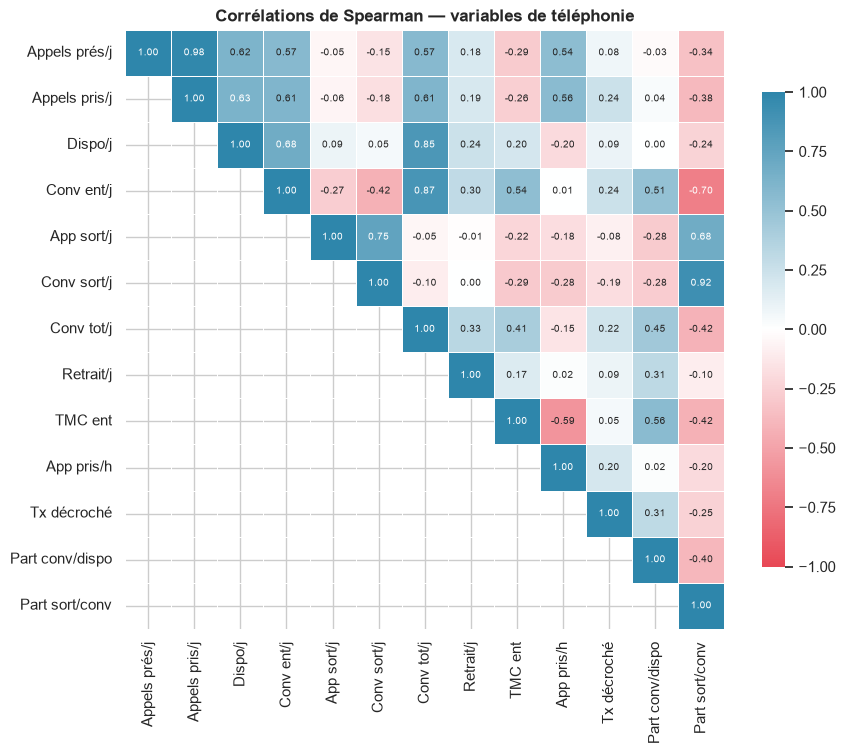

In [10]:
X_cor = df_trim[VARS_W].set_axis(LABELS_VARS, axis=1)
mat_cor = X_cor.corr(method="spearman")

masque = np.tril(np.ones_like(mat_cor, dtype=bool), k=-1)      # on ne garde que le triangle supérieur
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(mat_cor, mask=masque, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap=CMAP_DIV,
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Corrélations de Spearman — variables de téléphonie")
montre("correlations")

Les variables de volume entrants (appels présentés, appels pris, disponibilité, conversation) sont fortement corrélées entre elles, de même que conversation sortante et part de sortants. D'où l'intérêt de l'ACP.

## 4.2 Analyse en Composantes Principales (ACP)

L'ACP résume l'information de variables fortement corrélées en quelques axes indépendants, pour lever la redondance avant la classification. Les données sont centrées-réduites. L'ACP est calculée directement par diagonalisation de la matrice de corrélation (même convention que `FactoMineR::PCA`).

In [11]:
def acp(X, ncp=10):
    """ACP normée : valeurs propres, coordonnées des individus, corrélations variables-axes."""
    Z = (X - X.mean()) / X.std(ddof=0)
    vals, vecs = np.linalg.eigh(np.corrcoef(Z.to_numpy(), rowvar=False))
    o = vals.argsort()[::-1]
    vals, vecs = vals[o], vecs[:, o]
    for k in range(vecs.shape[1]):                      # convention de signe : plus forte corrélation > 0
        if vecs[np.abs(vecs[:, k]).argmax(), k] < 0:
            vecs[:, k] *= -1
    return {"eig": vals, "pct": vals / vals.sum() * 100, "coord": Z.to_numpy() @ vecs[:, :ncp],
            "load": (vecs * np.sqrt(vals))[:, :ncp], "vars": list(X.columns)}


X_acp = df_trim[VARS_W].set_axis(LABELS_VARS, axis=1)
ACP = acp(X_acp, ncp=10)
nb_axes = int((ACP["eig"] > 1).sum())                   # règle de Kaiser (valeur propre > 1)

pd.DataFrame({"Axe": [f"F{i}" for i in range(1, 11)],
              "Valeur propre": ACP["eig"][:10],
              "% variance": ACP["pct"][:10],
              "% cumulé": np.cumsum(ACP["pct"])[:10],
              "Kaiser": np.where(ACP["eig"][:10] > 1, "retenu", "—")}
             ).pipe(tab, f"Valeurs propres — {nb_axes} axes retenus (Kaiser)")

Axe,Valeur propre,% variance,% cumulé,Kaiser
F1,4.523,34.791,34.791,retenu
F2,2.836,21.819,56.610,retenu
F3,2.440,18.770,75.380,retenu
F4,1.269,9.758,85.138,retenu
F5,0.873,6.717,91.855,—
F6,0.569,4.375,96.230,—
F7,0.326,2.510,98.740,—
F8,0.073,0.562,99.302,—
F9,0.042,0.324,99.627,—
F10,0.024,0.181,99.808,—


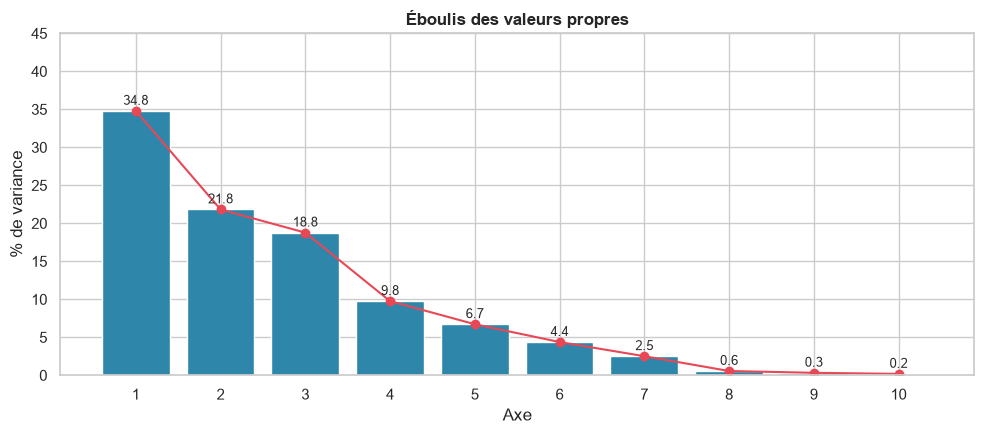

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(1, 11)
ax.bar(x, ACP["pct"][:10], color="#2E86AB", edgecolor="white")
ax.plot(x, ACP["pct"][:10], color="#E84855", marker="o")
for xi, p in zip(x, ACP["pct"][:10]):
    ax.text(xi, p + .8, f"{p:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xlabel("Axe"); ax.set_ylabel("% de variance"); ax.set_ylim(0, 45)
ax.set_title("Éboulis des valeurs propres")
montre("eboulis_acp")

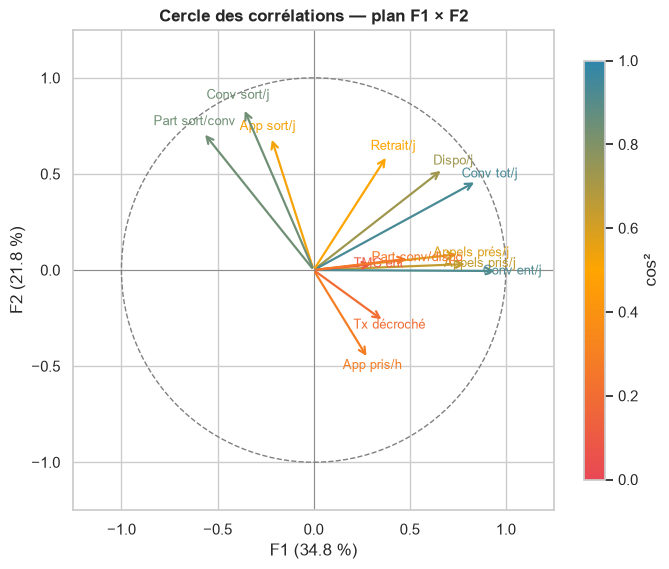

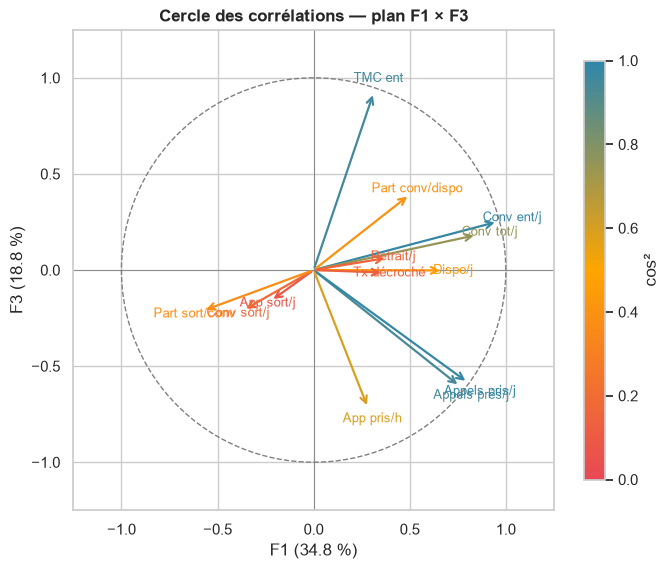

In [13]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def cercle_correlations(A, a, b):
    cmap = LinearSegmentedColormap.from_list("cos2", ["#E84855", "#FFA500", "#2E86AB"])
    L = A["load"]
    cos2 = L[:, a] ** 2 + L[:, b] ** 2
    fig, ax = plt.subplots(figsize=(7, 6.5))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", ls="--"))
    for i, nom in enumerate(A["vars"]):
        c = cmap(min(cos2[i], 1))
        ax.annotate("", xy=(L[i, a], L[i, b]), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=1.6))
        ax.text(L[i, a] * 1.08, L[i, b] * 1.08, nom, color=c, fontsize=9, ha="center", va="center")
    ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect("equal")
    ax.set_xlabel(f"F{a + 1} ({A['pct'][a]:.1f} %)"); ax.set_ylabel(f"F{b + 1} ({A['pct'][b]:.1f} %)")
    ax.set_title(f"Cercle des corrélations — plan F{a + 1} × F{b + 1}")
    plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=cmap), ax=ax, shrink=.7, label="cos²")
    montre()


cercle_correlations(ACP, 0, 1)
cercle_correlations(ACP, 0, 2)

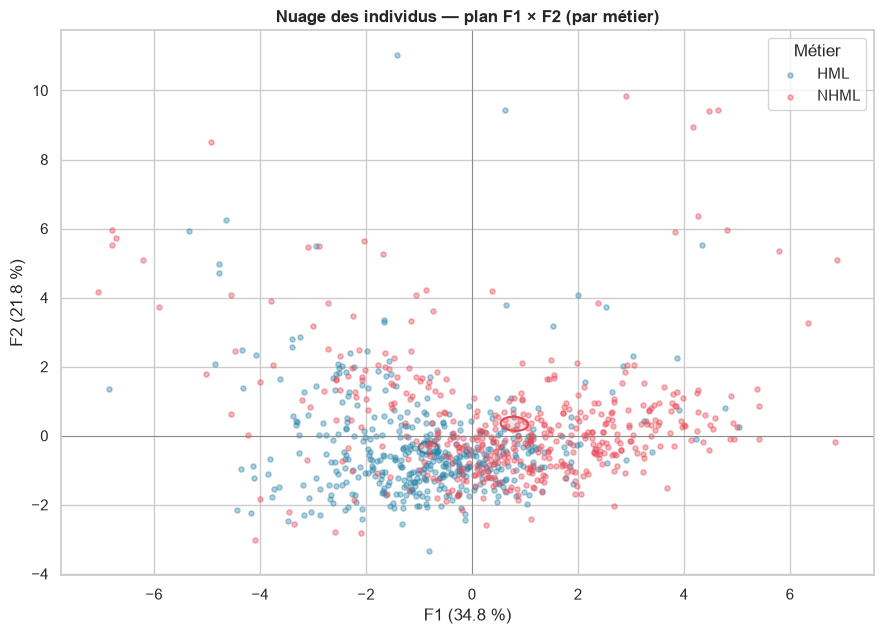

In [14]:
fig, ax = plt.subplots(figsize=(9, 6.5))
for m, couleur in COULEURS_METIER.items():
    pts = ACP["coord"][(df_trim["metier"] == m).to_numpy()][:, :2]
    ax.scatter(pts[:, 0], pts[:, 1], s=14, alpha=.4, color=couleur, label=m)
    ellipse(ax, pts, couleur, niveau=.95, de_la_moyenne=True)      # ellipse de confiance de la moyenne
ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
ax.set_xlabel(f"F1 ({ACP['pct'][0]:.1f} %)"); ax.set_ylabel(f"F2 ({ACP['pct'][1]:.1f} %)")
ax.set_title("Nuage des individus — plan F1 × F2 (par métier)"); ax.legend(title="Métier")
montre()

**Lecture des axes** (4 axes retenus par la règle de Kaiser, 85,1 % de la variance).

| Axe | % variance | Ce qu'il mesure | Variables les plus liées |
|---|---|---|---|
| F1 | 34,8 | Intensité de l'activité entrante | Conv. entrants/j (0,96), Conv. totale/j (0,85), Appels pris/j (0,80), Appels présentés/j (0,76) |
| F2 | 21,8 | Orientation vers les appels sortants | Conv. sortants/j (0,84), Part sortant/conv (0,72), Appels sortants/j (0,69), Retrait/j (0,60) |
| F3 | 18,8 | Durée des entretiens | TMC entrants (0,92), Appels pris/h (−0,72) |
| F4 | 9,8 | Utilisation du temps disponible | Part conv./dispo (0,70), Dispo/j (−0,47), Retrait/j (0,43) |

Le premier axe est un axe de volume, très lié au métier (les NHML sont à droite). Les axes 2 et 3 décrivent des *pratiques* : relancer ou non, faire des entretiens longs ou courts. Ils ne dépendent pas du métier.

## 4.3 Classification en 4 groupes

**Principe.** Une Classification Ascendante Hiérarchique (critère de Ward) forme d'abord des groupes d'observations proches ; un K-means, qui part des centres de la CAH, vérifie ensuite chaque observation une par une. Les deux méthodes travaillent sur les 4 axes de l'ACP.

### CAH et choix du nombre de classes

In [15]:
coords = ACP["coord"][:, :nb_axes]
Zw = linkage(coords, method="ward")                     # Ward sur distances euclidiennes (= ward.D2 de R)


def cutree(Z, k):
    """Coupe le dendrogramme en k classes, numérotées par ordre d'apparition (comme `cutree` de R)."""
    return pd.factorize(fcluster(Z, k, criterion="maxclust"))[0] + 1


seuil_k4 = (Zw[-3, 2] + Zw[-4, 2]) / 2                  # hauteur de coupure donnant 4 classes

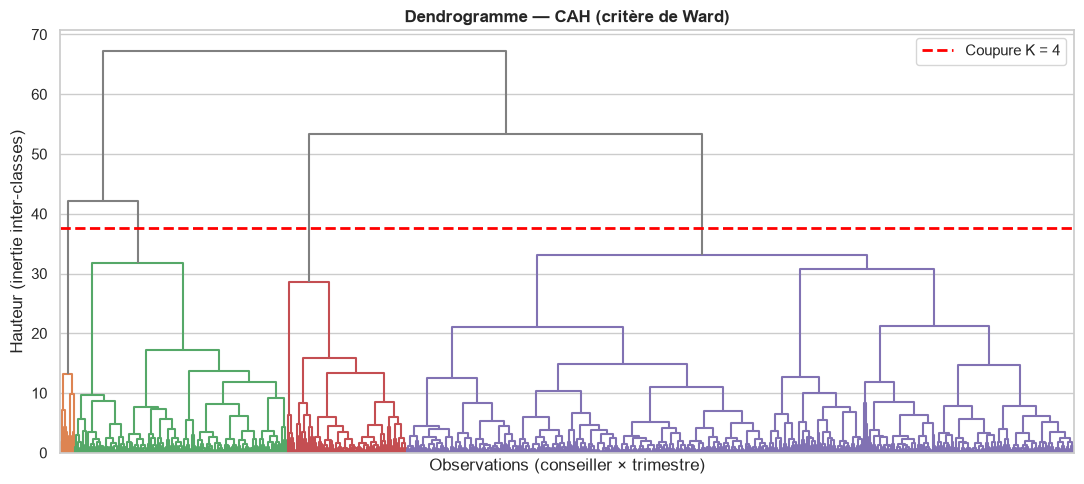

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(Zw, no_labels=True, color_threshold=seuil_k4, above_threshold_color="grey", ax=ax)
ax.axhline(seuil_k4, color="red", ls="--", lw=2, label="Coupure K = 4")
ax.set_title("Dendrogramme — CAH (critère de Ward)")
ax.set_xlabel("Observations (conseiller × trimestre)"); ax.set_ylabel("Hauteur (inertie inter-classes)")
ax.legend(loc="upper right")
montre()

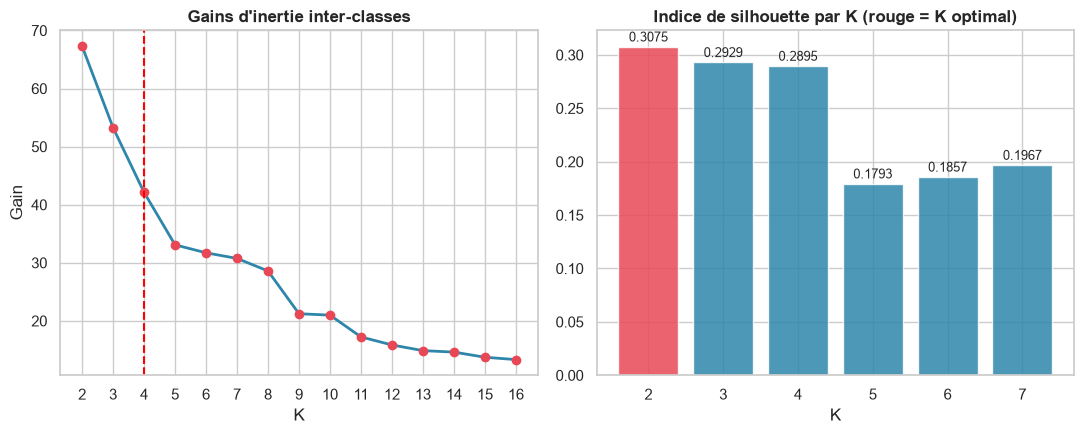

In [17]:
n_test = 15
df_gains = pd.DataFrame({"K": np.arange(2, n_test + 2), "Gain": Zw[::-1, 2][:n_test]})
df_sil = pd.DataFrame({"K": np.arange(2, 8),
                       "Silhouette": [silhouette_score(coords, cutree(Zw, k)) for k in range(2, 8)]})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(df_gains["K"], df_gains["Gain"], color="#2E86AB", lw=2, marker="o", mfc="#E84855", mec="#E84855")
axes[0].axvline(4, color="red", ls="--")
axes[0].set_xticks(df_gains["K"]); axes[0].set_title("Gains d'inertie inter-classes")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Gain")
k_opt = df_sil.loc[df_sil["Silhouette"].idxmax(), "K"]
axes[1].bar(df_sil["K"], df_sil["Silhouette"], color=np.where(df_sil["K"] == k_opt, "#E84855", "#2E86AB"), alpha=.85)
for k, s in zip(df_sil["K"], df_sil["Silhouette"]):
    axes[1].text(k, s + .005, f"{s:.4f}", ha="center", fontsize=9)
axes[1].set_title("Indice de silhouette par K (rouge = K optimal)"); axes[1].set_xlabel("K")
montre()

**Choix : K = 4.** L'indice de silhouette ne désigne pas clairement K = 4 : il vaut 0,31 pour K = 2, 0,29 pour K = 3 et 0,29 pour K = 4, puis chute à 0,18 pour K = 5. K = 2 se résumerait à « beaucoup ou peu d'activité », ce qui n'aide pas le management. K = 4 garde une silhouette du même niveau que K = 3 et sépare des pratiques différentes (relances, entretiens longs). C'est un choix d'interprétation, défendable sans être le seul possible.

### Affinage par K-means

In [18]:
K_FINAL = 4
groupes_cah = cutree(Zw, K_FINAL)
centres_init = np.vstack([coords[groupes_cah == g].mean(axis=0) for g in range(1, K_FINAL + 1)])

km = KMeans(n_clusters=K_FINAL, init=centres_init, n_init=1, max_iter=200,
            algorithm="lloyd", random_state=42).fit(coords)

# Les numéros de classes sont arbitraires : on rattache chaque classe à G1..G4 d'après sa signature
# (G1 = plus forte conversation sortante ; G3 = plus forte part de sortants parmi les restantes ;
#  G2 = plus forte conversation entrante parmi les restantes ; G4 = le reste).
def aligner_groupes(labels, df):
    m = df.assign(c=labels).groupby("c")[["conv_sortants_min_j_w", "part_sortant_conv_w",
                                          "conv_entrants_min_j_w"]].mean()
    reste = list(m.index)
    g1 = m.loc[reste, "conv_sortants_min_j_w"].idxmax(); reste.remove(g1)
    g3 = m.loc[reste, "part_sortant_conv_w"].idxmax(); reste.remove(g3)
    g2 = m.loc[reste, "conv_entrants_min_j_w"].idxmax(); reste.remove(g2)
    return pd.Series(labels).map({g1: 1, g2: 2, g3: 3, reste[0]: 4}).to_numpy()


df_trim_acp = df_trim.copy()
df_trim_acp["groupe"] = aligner_groupes(km.labels_, df_trim_acp)

inertie_totale = ((coords - coords.mean(axis=0)) ** 2).sum()
print("Effectifs par groupe :")
print(df_trim_acp["groupe"].value_counts().sort_index().to_string())
print("\nRatio inertie inter / totale :", round((1 - km.inertia_ / inertie_totale) * 100, 1), "%")
print("\nConcordance CAH / K-means :")
print(pd.crosstab(pd.Series(groupes_cah, name="CAH"), pd.Series(km.labels_ + 1, name="Kmeans")))

Effectifs par groupe :
groupe
1     13
2    288
3    139
4    467

Ratio inertie inter / totale : 48.4 %

Concordance CAH / K-means :
Kmeans    1    2    3   4
CAH                      
1       190    0    0   0
2        98  467   32   0
3         0    0  107   0
4         0    0    0  13


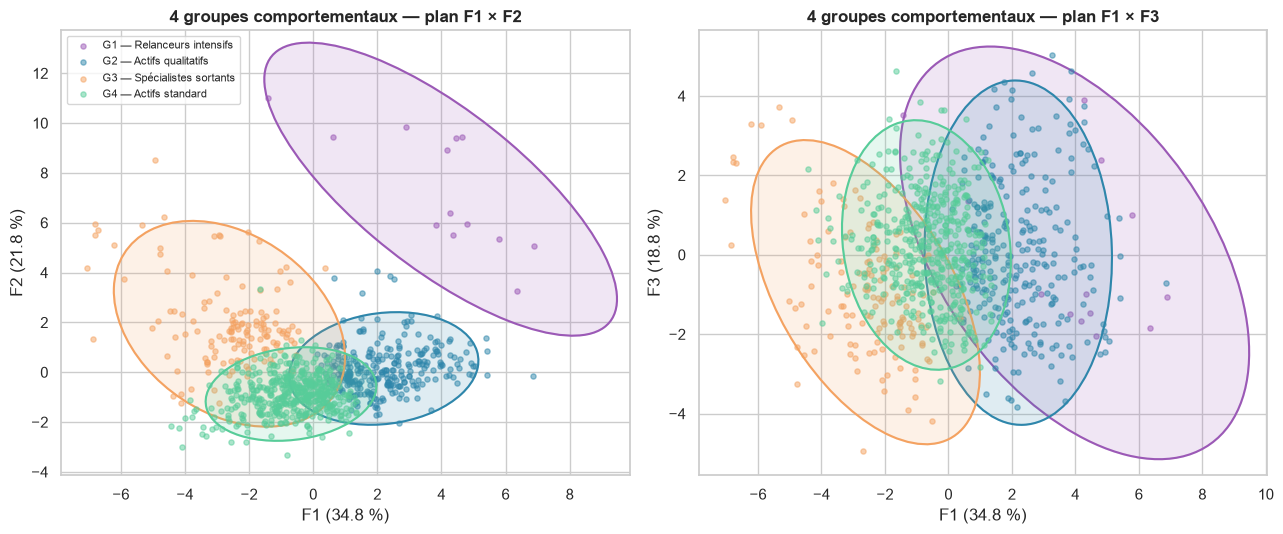

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    for g in range(1, 5):
        pts = coords[(df_trim_acp["groupe"] == g).to_numpy()][:, [a, b]]
        ax.scatter(pts[:, 0], pts[:, 1], s=14, alpha=.5, color=PALETTE[g], label=NOMS_GROUPES[g])
        ellipse(ax, pts, PALETTE[g], niveau=.95)
    ax.set_xlabel(f"F{a + 1} ({ACP['pct'][a]:.1f} %)"); ax.set_ylabel(f"F{b + 1} ({ACP['pct'][b]:.1f} %)")
    ax.set_title(f"4 groupes comportementaux — plan F{a + 1} × F{b + 1}")
axes[0].legend(fontsize=8)
montre("groupes_acp")

**Qualité de la partition.** Après le K-means, la silhouette vaut **0,27** et la classification explique **48,4 % de l'inertie totale**. Les groupes sont réels mais pas parfaitement séparés : une partie des observations se situe entre deux profils.

*Note : le K-means de R utilise l'algorithme de Hartigan-Wong, celui de scikit-learn l'algorithme de Lloyd. À partir des mêmes centres de départ, les partitions sont très proches mais pas forcément identiques à l'observation près.*

## 4.4 Profils des 4 groupes

In [20]:
profils = (df_trim_acp.groupby("groupe")
           .agg(N=("groupe", "size"), pct_HML=("metier", lambda s: (s == "HML").mean() * 100),
                **{v: (v, "mean") for v in VARS_W}))

moy_glob = df_trim_acp[VARS_W].mean()
indices = (profils[VARS_W] / moy_glob * 100).round(0)
indices.columns = LABELS_VARS
indices.index.name = "Groupe"

tab(indices.reset_index(), "Indices comportementaux (100 = moyenne globale)", precision=0)

Groupe,Appels prés/j,Appels pris/j,Dispo/j,Conv ent/j,App sort/j,Conv sort/j,Conv tot/j,Retrait/j,TMC ent,App pris/h,Tx décroché,Part conv/dispo,Part sort/conv
1,137,132,130,147,280,423,176,795,113,101,96,139,262
2,121,123,121,134,86,58,124,117,110,101,101,103,45
3,87,85,99,58,148,287,87,80,74,88,98,90,306
4,90,90,87,90,89,61,87,76,101,103,100,100,68


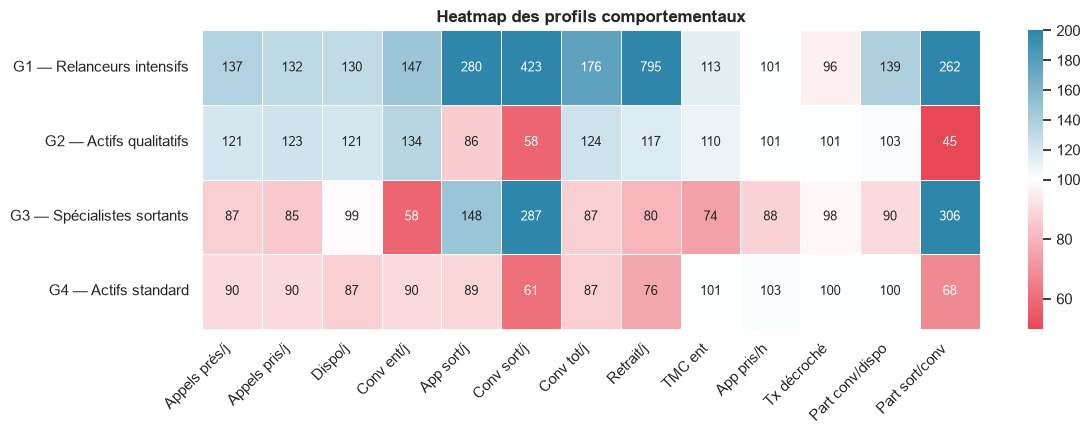

In [21]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(indices.rename(index=NOMS_GROUPES), annot=True, fmt=".0f", cmap=CMAP_DIV,
            norm=TwoSlopeNorm(100, 50, 200), linewidths=.5, annot_kws={"size": 9}, ax=ax)
ax.set_title("Heatmap des profils comportementaux"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
montre("profils_groupes")

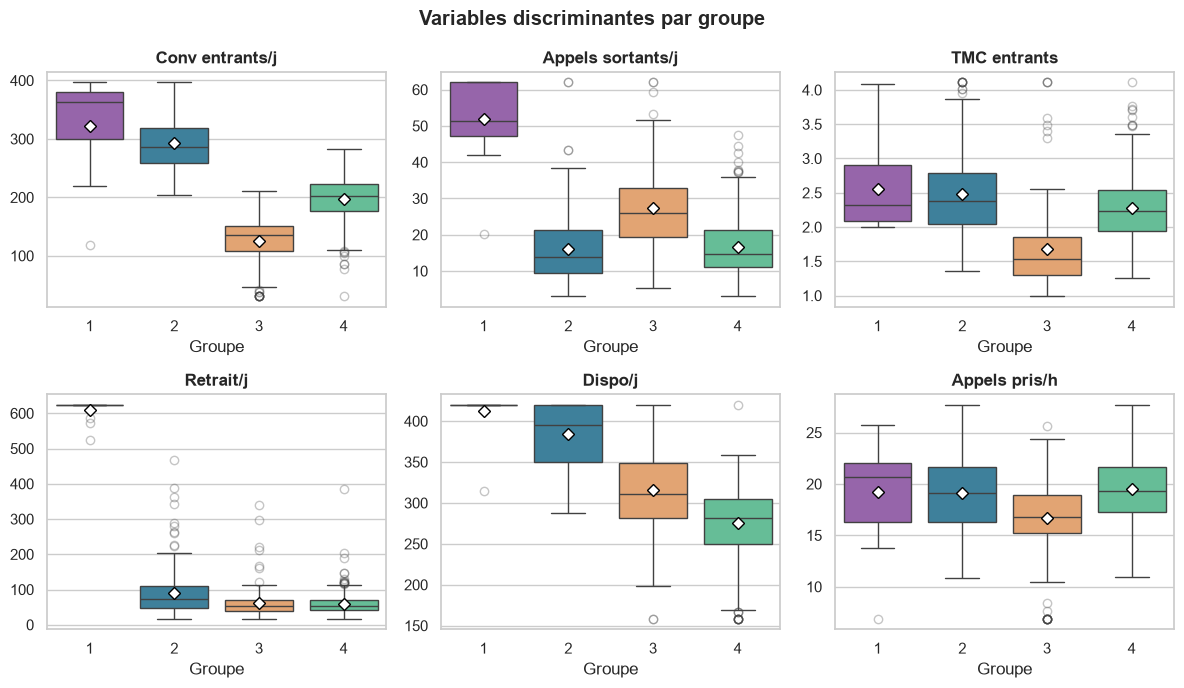

In [22]:
vars_cles = ["conv_entrants_min_j_w", "appels_sortants_j_w", "tmc_entrants_w",
             "retrait_min_j_w", "dispo_min_j_w", "appels_pris_h_w"]
labels_cles = ["Conv entrants/j", "Appels sortants/j", "TMC entrants",
               "Retrait/j", "Dispo/j", "Appels pris/h"]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, v, l in zip(axes.ravel(), vars_cles, labels_cles):
    sns.boxplot(data=df_trim_acp, x="groupe", y=v, hue="groupe", palette=PALETTE, legend=False,
                showmeans=True, meanprops=dict(marker="D", mfc="white", mec="black"),
                flierprops=dict(alpha=.3), ax=ax)
    ax.set_title(l); ax.set_xlabel("Groupe"); ax.set_ylabel("")
fig.suptitle("Variables discriminantes par groupe", fontweight="bold")
montre()

**Les quatre groupes.**

| Groupe | N | % HML | Signature (indices, 100 = moyenne) |
|---|---|---|---|
| G1 : relanceurs intensifs | 13 (1,4 %) | 23 % | Appels sortants 280, conv. sortants 423, retrait 795, conv. entrants 147 |
| G2 : actifs qualitatifs | 288 (31,8 %) | 21 % | Conv. entrants 134, appels pris 123, TMC 110, part de sortants 45 |
| G3 : spécialistes sortants | 139 (15,3 %) | 45 % | Part de sortants 306, conv. sortants 287, conv. entrants 58, TMC 74 |
| G4 : actifs standard | 467 (51,5 %) | 70 % | Proche de la moyenne, un peu en retrait sur les volumes (dispo 87, conv. sortants 61) |

### Interprétation

*Les noms résument la façon de travailler de chaque groupe ; les explications sur les causes sont des pistes de lecture, pas des résultats démontrés.*

* **G1, relanceurs intensifs (N = 13).** Groupe minuscule et très marqué : beaucoup d'entrants et énormément de relances et de retrait. Trop petit pour en tirer des règles générales.
* **G2, actifs qualitatifs (N = 288, 79 % de NHML).** Ils traitent beaucoup d'appels entrants, avec des entretiens un peu plus longs que la moyenne, et relancent très peu.
* **G3, spécialistes sortants (N = 139).** Ils consacrent une grande part de leur conversation aux relances. En contrepartie, la conversation entrante s'effondre (indice 58) et la productivité horaire baisse (88).
* **G4, actifs standard (N = 467, 70 % de HML).** La moitié des observations : le comportement moyen de la plateforme, un peu en retrait sur les volumes. La forte part de HML peut l'expliquer, une partie de leur temps allant aux études de crédit en ligne.

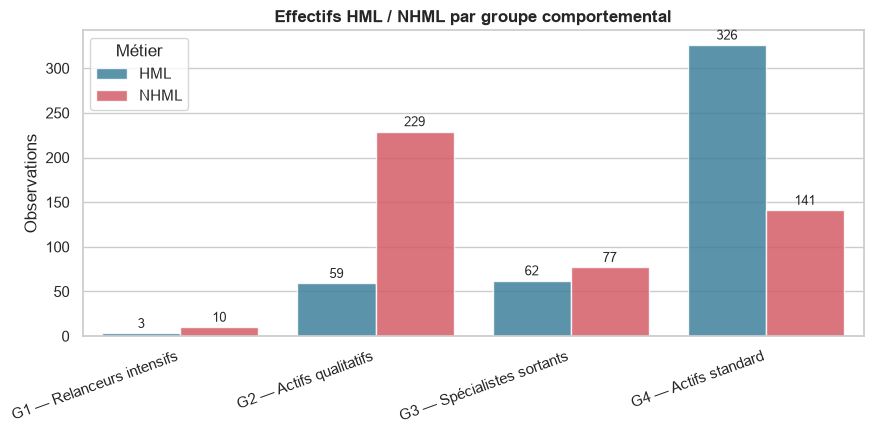

In [23]:
rep = df_trim_acp.groupby(["groupe", "metier"]).size().reset_index(name="n")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=rep, x="groupe", y="n", hue="metier", palette=COULEURS_METIER, alpha=.85, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fontsize=9, padding=2)
ax.set_xticks(range(4)); ax.set_xticklabels([NOMS_GROUPES[g] for g in range(1, 5)], rotation=20, ha="right")
ax.set_xlabel(""); ax.set_ylabel("Observations"); ax.legend(title="Métier")
ax.set_title("Effectifs HML / NHML par groupe comportemental")
montre()

---
# 5. Mission 1 — Validation et modèle d'affectation (analyse discriminante)

**Question.** Les 4 groupes sont-ils statistiquement distincts et *reproductibles* sur de nouvelles données ? Peut-on y affecter rapidement un nouveau conseiller sans refaire toute la classification ?

## 5.1 Base et conditions d'application

In [24]:
df_lda = (df_trim_acp[["code_op", "trimestre", "metier", "groupe"] + VARS_W]
          .dropna().reset_index(drop=True))

(df_lda.groupby("groupe")
 .agg(N=("groupe", "size"), **{"% HML": ("metier", lambda s: (s == "HML").mean() * 100)})
 .round(1).assign(Nom=lambda d: d.index.map(NOMS_GROUPES)).reset_index()
 .pipe(tab, "Effectifs par groupe (règle : au moins p + 1 = 14 observations par groupe)", precision=1))

groupe,N,% HML,Nom
1,13,23.1,G1 — Relanceurs intensifs
2,288,20.5,G2 — Actifs qualitatifs
3,139,44.6,G3 — Spécialistes sortants
4,467,69.8,G4 — Actifs standard


La LDA suppose l'égalité des matrices de covariance entre groupes et un effectif minimal de p + 1 observations par groupe. Le groupe G1 (N = 13) **ne respecte pas strictement** cette condition : ses résultats discriminants sont à interpréter avec prudence (voir les limites).

## 5.2 Estimation

In [25]:
X_lda = df_lda[VARS_W].to_numpy()
y_lda = df_lda["groupe"].to_numpy()

# A priori équiprobables : les 4 groupes pèsent autant dans l'affectation
modele_lda = LinearDiscriminantAnalysis(solver="svd", priors=[.25, .25, .25, .25]).fit(X_lda, y_lda)

pct_var = modele_lda.explained_variance_ratio_ * 100
fd_df = pd.DataFrame({"Fonction": [f"LD{i + 1}" for i in range(len(pct_var))],
                      "Pct_variance": pct_var, "Pct_cumulée": np.cumsum(pct_var)})
tab(fd_df, "Fonctions discriminantes (K − 1 = 3) — variance discriminante expliquée", precision=2)

Fonction,Pct_variance,Pct_cumulée
LD1,87.27,87.27
LD2,10.25,97.52
LD3,2.48,100.00


**Lecture.** La première fonction discriminante porte presque toute la séparation (87 % de la variance entre groupes) ; avec la deuxième, on atteint 97,5 %. Les deux premières suffisent donc pour représenter les groupes sur un plan.

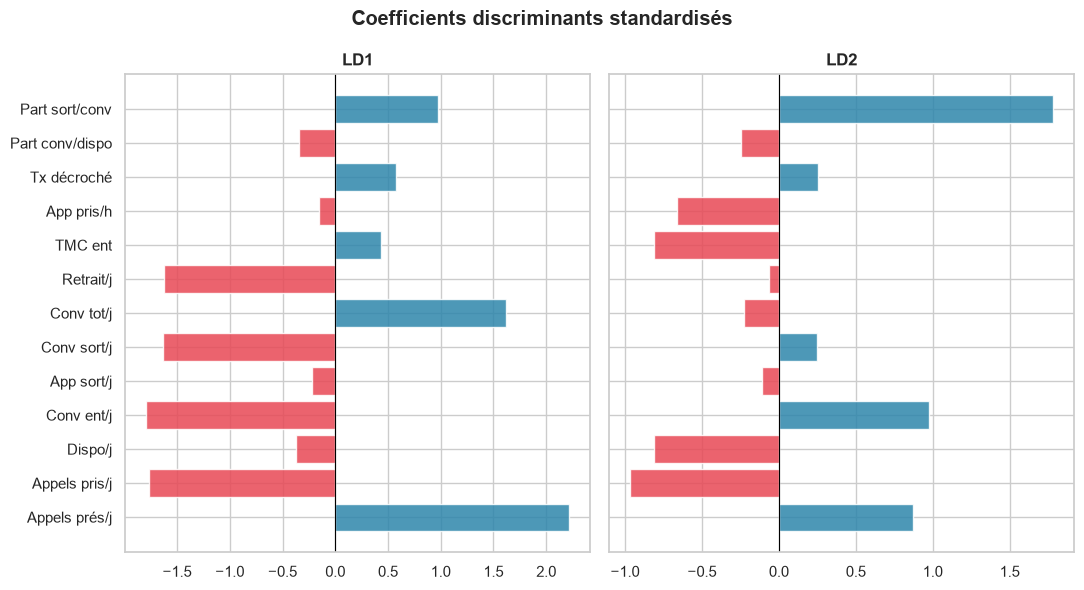

In [26]:
# Coefficients standardisés = coefficients bruts × écart-type de chaque variable
coef_std = pd.DataFrame(modele_lda.scalings_[:, :3] * df_lda[VARS_W].std().to_numpy()[:, None],
                        index=LABELS_VARS, columns=["LD1", "LD2", "LD3"])

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, ld in zip(axes, ["LD1", "LD2"]):
    c = coef_std[ld]
    ax.barh(c.index, c.values, color=np.where(c.values > 0, "#2E86AB", "#E84855"), alpha=.85)
    ax.axvline(0, color="black", lw=.8); ax.set_title(ld); ax.invert_yaxis()
fig.suptitle("Coefficients discriminants standardisés", fontweight="bold")
montre()

## 5.3 Performance : apprentissage et validation croisée Leave-One-Out

Deux mesures : le **taux de bien classés (TBC)** sur l'échantillon d'apprentissage (optimiste, le modèle a été ajusté sur ces données) et le **TBC en validation croisée Leave-One-Out** (chaque observation est prédite par un modèle entraîné sans elle : mesure non biaisée, à retenir pour l'usage opérationnel). L'écart entre les deux mesure le sur-apprentissage.

In [27]:
GROUPES = [1, 2, 3, 4]

pred_train = modele_lda.predict(X_lda)
proba_train = modele_lda.predict_proba(X_lda)
ld_train = modele_lda.transform(X_lda)
df_lda["groupe_predit"] = pred_train
df_lda["proba_max"] = proba_train.max(axis=1)
df_lda["LD1"], df_lda["LD2"] = ld_train[:, 0], ld_train[:, 1]


def matrice_confusion(reel, predit):
    return pd.crosstab(reel, predit, rownames=["Réel"], colnames=["Prédit"]).reindex(
        index=GROUPES, columns=GROUPES, fill_value=0)


conf_mat = matrice_confusion(df_lda["groupe"], df_lda["groupe_predit"])
tbc_global = np.trace(conf_mat) / conf_mat.to_numpy().sum() * 100
tbc_groupe = np.diag(conf_mat) / conf_mat.sum(axis=1) * 100

# Validation croisée Leave-One-Out (a priori fixés aux proportions observées, comme MASS::lda(CV = TRUE))
priors_obs = df_lda["groupe"].value_counts(normalize=True).sort_index().to_numpy()
pred_loo = cross_val_predict(LinearDiscriminantAnalysis(solver="svd", priors=priors_obs),
                             X_lda, y_lda, cv=LeaveOneOut())
conf_loo = matrice_confusion(df_lda["groupe"], pred_loo)
tbc_loo = np.trace(conf_loo) / conf_loo.to_numpy().sum() * 100
tbc_loo_groupe = np.diag(conf_loo) / conf_loo.sum(axis=1) * 100

print(f"TBC apprentissage : {tbc_global:.1f} % | TBC LOO : {tbc_loo:.1f} %\n")
pd.DataFrame({"Groupe": [NOMS_GROUPES[g] for g in GROUPES], "N": conf_mat.sum(axis=1).to_numpy(),
              "TBC apprentissage": [f"{x:.1f} %" for x in tbc_groupe],
              "TBC LOO": [f"{x:.1f} %" for x in tbc_loo_groupe]}
             ).pipe(tab, "TBC par groupe : apprentissage vs validation croisée")

TBC apprentissage : 95.5 % | TBC LOO : 92.4 %



Groupe,N,TBC apprentissage,TBC LOO
G1 — Relanceurs intensifs,13,100.0 %,92.3 %
G2 — Actifs qualitatifs,288,95.5 %,85.8 %
G3 — Spécialistes sortants,139,84.2 %,82.0 %
G4 — Actifs standard,467,98.7 %,99.6 %


**Lecture.** Le modèle classe bien **95,5 %** des observations sur l'apprentissage et **92,4 %** en validation croisée Leave-One-Out : l'écart est faible, il n'y a pas de sur-apprentissage notable. G4 est presque toujours bien reconnu (99,6 %), G3 l'est le moins (82 %). G1 (N = 13) est sous le minimum théorique de 14 observations : son taux est à lire avec prudence.

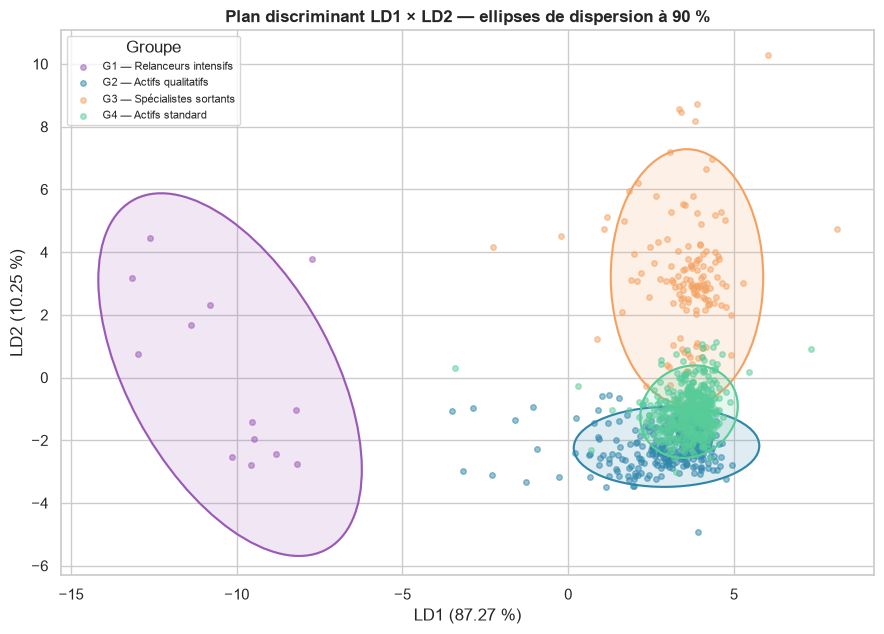

In [28]:
fig, ax = plt.subplots(figsize=(9, 6.5))
for g in GROUPES:
    pts = df_lda.loc[df_lda["groupe"] == g, ["LD1", "LD2"]].to_numpy()
    ax.scatter(pts[:, 0], pts[:, 1], s=16, alpha=.5, color=PALETTE[g], label=NOMS_GROUPES[g])
    ellipse(ax, pts, PALETTE[g], niveau=.90)
ax.set_xlabel(f"LD1 ({fd_df.loc[0, 'Pct_variance']:.2f} %)"); ax.set_ylabel(f"LD2 ({fd_df.loc[1, 'Pct_variance']:.2f} %)")
ax.set_title("Plan discriminant LD1 × LD2 — ellipses de dispersion à 90 %"); ax.legend(title="Groupe", fontsize=8)
montre("plan_discriminant")

## 5.4 Le modèle d'affectation opérationnel

Le modèle est encapsulé dans une fonction réutilisable : il suffit de renseigner les 13 indicateurs d'un conseiller (normalisés) pour obtenir son **groupe prédit**, ses **probabilités d'appartenance** aux 4 groupes et ses **scores LD1/LD2** pour le positionner visuellement. Cela permet un suivi trimestriel automatisé et une **alerte précoce** en cas de changement de profil.

In [29]:
def predire_groupe(profil_df, modele=modele_lda):
    """Affecte un ou plusieurs conseillers (13 indicateurs *_w en colonnes) à un groupe comportemental."""
    X = profil_df[VARS_W].to_numpy()
    proba, ld = modele.predict_proba(X), modele.transform(X)
    out = pd.DataFrame({"groupe_predit": modele.predict(X)})
    out["nom_groupe"] = out["groupe_predit"].map(NOMS_GROUPES)
    for i, g in enumerate(modele.classes_):
        out[f"proba_G{g}"] = proba[:, i].round(4)
    out["score_LD1"], out["score_LD2"] = ld[:, 0].round(4), ld[:, 1].round(4)
    return out


# Exemple : profil fictif très orienté entrants, peu de relances
profil_test = pd.DataFrame([{
    "appels_presentes_j_w": 115, "appels_pris_j_w": 108, "dispo_min_j_w": 340,
    "conv_entrants_min_j_w": 260, "appels_sortants_j_w": 12, "conv_sortants_min_j_w": 15,
    "conv_totale_j_w": 275, "retrait_min_j_w": 90, "tmc_entrants_w": 2.5,
    "appels_pris_h_w": 19, "taux_decroche_w": .94, "part_conv_dispo_w": .81,
    "part_sortant_conv_w": .05}])
tab(predire_groupe(profil_test), "Exemple d'affectation d'un profil fictif", precision=4)

groupe_predit,nom_groupe,proba_G1,proba_G2,proba_G3,proba_G4,score_LD1,score_LD2
2,G2 — Actifs qualitatifs,0.0000,0.6958,0.0000,0.3042,3.0463,-2.0611


---
# 6. Mission 1 — Migrations entre trimestres

**Question.** Un conseiller reste-t-il dans le même groupe d'un trimestre à l'autre ? Les groupes sont-ils une posture durable ou une situation passagère ? Une stabilité raisonnable est nécessaire pour que les groupes aient une valeur descriptive et managériale.

In [30]:
ordre_trim = ["1 03", "2 03", "3 03", "4 03", "1 04", "2 04", "3 04", "4 04"]
rang_trim = {t: i for i, t in enumerate(ordre_trim)}

df_trans = (df_lda[["code_op", "trimestre", "groupe"]]
            .assign(rang=lambda d: d["trimestre"].map(rang_trim))
            .sort_values(["code_op", "rang"]).reset_index(drop=True))
df_trans["groupe_suivant"] = df_trans.groupby("code_op")["groupe"].shift(-1)
df_trans["rang_suivant"] = df_trans.groupby("code_op")["rang"].shift(-1)
df_trans = df_trans.dropna(subset=["groupe_suivant"]).astype({"groupe_suivant": int})

mat_trans = (pd.crosstab(df_trans["groupe"], df_trans["groupe_suivant"], rownames=["Départ"], colnames=["Arrivée"])
             .reindex(index=GROUPES, columns=GROUPES, fill_value=0))
mat_trans_pct = mat_trans.div(mat_trans.sum(axis=1), axis=0) * 100
taux_stabilite = np.trace(mat_trans) / mat_trans.to_numpy().sum() * 100
n_saut = int((df_trans["rang_suivant"] - df_trans["rang"] != 1).sum())

print(f"Transitions observées : {len(df_trans)} | Stabilité globale : {taux_stabilite:.1f} %")
print(f"(dont {n_saut} transition(s) vers une observation non adjacente : conseiller absent un trimestre intermédiaire)\n")
print(mat_trans_pct.round(1))

Transitions observées : 656 | Stabilité globale : 49.1 %
(dont 8 transition(s) vers une observation non adjacente : conseiller absent un trimestre intermédiaire)

Arrivée     1     2     3     4
Départ                         
1        50.0  20.0  10.0  20.0
2         1.6  36.3  15.0  47.2
3         0.0  14.2  18.9  67.0
4         0.9  12.7  21.0  65.4


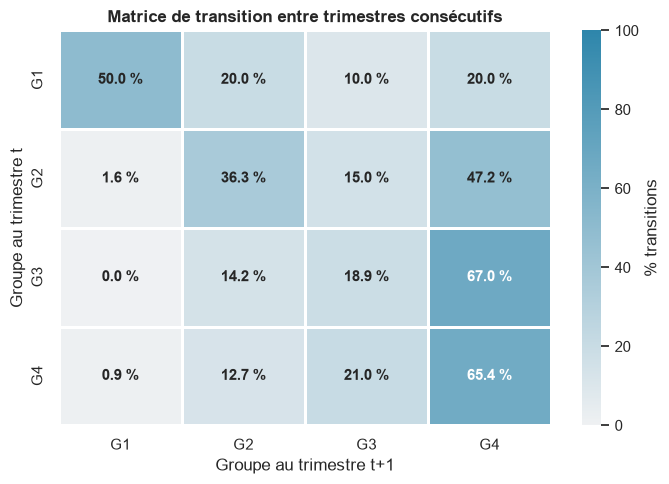

In [31]:
lab = [f"G{g}" for g in GROUPES]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(mat_trans_pct.set_axis(lab, axis=0).set_axis(lab, axis=1), annot=mat_trans_pct.round(1).astype(str).to_numpy() + " %",
            fmt="", cmap=sns.light_palette("#2E86AB", as_cmap=True), vmin=0, vmax=100, linewidths=.8,
            annot_kws={"fontweight": "bold", "size": 11}, cbar_kws={"label": "% transitions"}, ax=ax)
ax.set_title("Matrice de transition entre trimestres consécutifs")
ax.set_xlabel("Groupe au trimestre t+1"); ax.set_ylabel("Groupe au trimestre t")
montre("migrations")

In [32]:
(pd.DataFrame({"Groupe": [NOMS_GROUPES[g] for g in GROUPES],
               "N départs": mat_trans.sum(axis=1).to_numpy(),
               "N stables": np.diag(mat_trans),
               "% stable": np.diag(mat_trans_pct)})
 .sort_values("% stable", ascending=False)
 .pipe(tab, "Taux de stabilité par groupe", precision=1))

Groupe,N départs,N stables,% stable
G4 — Actifs standard,347,227,65.4
G1 — Relanceurs intensifs,10,5,50.0
G2 — Actifs qualitatifs,193,70,36.3
G3 — Spécialistes sortants,106,20,18.9


**Lecture.** Les groupes sont **moins stables que ce que disait le rapport d'origine** : d'un trimestre au suivant, 49 % des conseillers restent dans le même groupe.

* **G4 est le groupe le plus stable** (65 %) et sert de point d'arrivée : 47 % des actifs qualitatifs et 67 % des spécialistes sortants y passent au trimestre suivant.
* **G2 (36 %) et G3 (19 %) sont peu stables.** Ces profils ressemblent davantage à des périodes qu'à des postures durables.
* Pour G1, 10 transitions seulement : impossible de conclure.

Conséquence pour le management : le groupe d'un conseiller sur un trimestre est une information utile, mais il faut suivre son évolution plutôt que l'étiqueter une fois pour toutes.

---
# 7. Mission 2 — Performance commerciale par groupe

**Question.** Le comportement téléphonique d'un conseiller est-il prédictif de ses ventes ? Les groupes se distinguent-ils sur les ventes de la gamme : Formule Libravou (ouvertures, augmentations), crédit amortissable non affecté et affecté, assurance, chiffre d'affaires financé ?

## 7.1 Données de ventes : agrégation, normalisation, jointure

Comme pour la téléphonie, les ventes sont **agrégées au trimestre** (délai de comptabilisation des contrats) et **rapportées au nombre de jours de présence** (même `nb_jours_trim` que la phase 1).

In [33]:
nb_jours_ref = df_trim_acp[["code_op", "trimestre", "nb_jours_trim"]]

COLONNES_VENTES = {
    "FL SE Nombre d'ouvertures": "fl_se_ouv", "FL SE Montant financé sur ouvertures": "fl_se_montant",
    "AUG FL SE Nb total d'acceptés": "aug_fl_se_nb", "AUG FL SE Montant financé sur augmentations": "aug_fl_se_mnt",
    "FL MTL Nombre d'ouvertures": "fl_mtl_ouv", "FL MTL Montant financé": "fl_mtl_montant",
    "AUG FL MTL Nb total d'acceptés": "aug_fl_mtl_nb", "AUG FL MTL Montant financé sur augmentations": "aug_fl_mtl_mnt",
    "AMO NON-AFF SE Nombres d'ouvertures": "amo_na_se_ouv", "AMO NON-AFF SE Montant financé": "amo_na_se_mnt",
    "AMO NON-AFF MTL Nombres d'ouvertures": "amo_na_mtl_ouv", "AMO NON-AFF MTL Montant financé": "amo_na_mtl_mnt",
    "AMO AFFECTE SE Nombre d'ouvertures": "amo_af_se_ouv", "AMO AFFECTE SE Montant financé": "amo_af_se_mnt",
    "AMO AFFECTE MTL Nombre d'ouvertures": "amo_af_mtl_ouv", "AMO AFFECTE MTL Montant financé": "amo_af_mtl_mnt",
    "nombre de mises en place": "assur_mises", "nombre de mises en place.1": "assur_mises2",
}

v = (df_raw.rename(columns={"code OP": "code_op", "métier 2": "metier", **COLONNES_VENTES})
     [["trimestre", "code_op", "metier", *COLONNES_VENTES.values()]].copy())
v["code_op"] = v["code_op"].astype(str).str.strip()
v["trimestre"] = v["trimestre"].astype(str).str.strip()
cols_num = list(COLONNES_VENTES.values())
v[cols_num] = v[cols_num].apply(pd.to_numeric, errors="coerce")

# Regroupement SE (sans étude) + MTL (montage en ligne) puis agrégation trimestrielle
v = v.assign(fl_ouv=v.fl_se_ouv + v.fl_mtl_ouv, fl_mnt=v.fl_se_montant + v.fl_mtl_montant,
             aug_nb=v.aug_fl_se_nb + v.aug_fl_mtl_nb, aug_mnt=v.aug_fl_se_mnt + v.aug_fl_mtl_mnt,
             na_ouv=v.amo_na_se_ouv + v.amo_na_mtl_ouv, na_mnt=v.amo_na_se_mnt + v.amo_na_mtl_mnt,
             af_ouv=v.amo_af_se_ouv + v.amo_af_mtl_ouv, af_mnt=v.amo_af_se_mnt + v.amo_af_mtl_mnt,
             assur=v.assur_mises + v.assur_mises2)

df_ventes_trim = (v.groupby(["code_op", "trimestre"], as_index=False)
                  .agg(metier=("metier", "first"), fl_ouv_total=("fl_ouv", "sum"), fl_mnt_total=("fl_mnt", "sum"),
                       aug_fl_nb=("aug_nb", "sum"), aug_fl_mnt=("aug_mnt", "sum"),
                       amo_na_ouv=("na_ouv", "sum"), amo_na_mnt=("na_mnt", "sum"),
                       amo_af_ouv=("af_ouv", "sum"), amo_af_mnt=("af_mnt", "sum"),
                       assur_total=("assur", "sum"))
                  .merge(nb_jours_ref, on=["code_op", "trimestre"], how="left")
                  .rename(columns={"nb_jours_trim": "nb_jours_tot"}))
df_ventes_trim = df_ventes_trim[df_ventes_trim["nb_jours_tot"] > 0].copy()

d = df_ventes_trim
df_ventes_trim = d.assign(
    ca_total=d.fl_mnt_total + d.aug_fl_mnt + d.amo_na_mnt + d.amo_af_mnt,
    ouv_total=d.fl_ouv_total + d.aug_fl_nb + d.amo_na_ouv + d.amo_af_ouv)
d = df_ventes_trim
df_ventes_trim = d.assign(
    fl_ouv_j=d.fl_ouv_total / d.nb_jours_tot, aug_fl_nb_j=d.aug_fl_nb / d.nb_jours_tot,
    amo_na_ouv_j=d.amo_na_ouv / d.nb_jours_tot, amo_af_ouv_j=d.amo_af_ouv / d.nb_jours_tot,
    assur_j=d.assur_total / d.nb_jours_tot, ca_total_j=d.ca_total / d.nb_jours_tot,
    ouv_total_j=d.ouv_total / d.nb_jours_tot)

VARS_PERF = ["fl_ouv_j", "aug_fl_nb_j", "amo_na_ouv_j", "amo_af_ouv_j", "assur_j", "ca_total_j", "ouv_total_j"]
LABELS_PERF = ["FL Ouvertures/j", "AUG FL Nb/j", "AMO NA Ouvertures/j", "AMO Affecté Ouv/j",
               "Assurances/j", "CA total/j", "Ouvertures totales/j"]

# Jointure avec le groupe comportemental du même conseiller et du même trimestre
df_perf = df_ventes_trim.merge(df_lda[["code_op", "trimestre", "groupe"]], on=["code_op", "trimestre"], how="inner")
df_perf["trimestre"] = pd.Categorical(df_perf["trimestre"], categories=ordre_trim, ordered=True)

print("Base performances + groupes :", len(df_perf), "observations")

Base performances + groupes : 907 observations


## 7.2 Statistiques descriptives et indices

In [34]:
moy_groupes = (df_perf.groupby("groupe")[VARS_PERF].mean()
               .set_axis(LABELS_PERF, axis=1)
               .assign(N=df_perf.groupby("groupe").size(),
                       Groupe=lambda d: d.index.map(NOMS_GROUPES))
               .reset_index(drop=True)[["Groupe", "N", *LABELS_PERF]])
tab(moy_groupes, "Performances moyennes par groupe (par jour de présence)")

moy_glob_perf = df_perf[VARS_PERF].mean()
indices_perf = (df_perf.groupby("groupe")[VARS_PERF].mean() / moy_glob_perf * 100).round(0)

Groupe,N,FL Ouvertures/j,AUG FL Nb/j,AMO NA Ouvertures/j,AMO Affecté Ouv/j,Assurances/j,CA total/j,Ouvertures totales/j
G1 — Relanceurs intensifs,13,1.022,5.069,0.058,0.336,1.389,11465.161,6.485
G2 — Actifs qualitatifs,288,0.774,5.255,0.118,0.149,1.855,8695.343,6.296
G3 — Spécialistes sortants,139,0.973,3.048,0.022,0.142,2.806,6513.415,4.184
G4 — Actifs standard,467,0.957,4.076,0.123,0.184,2.294,8168.821,5.339


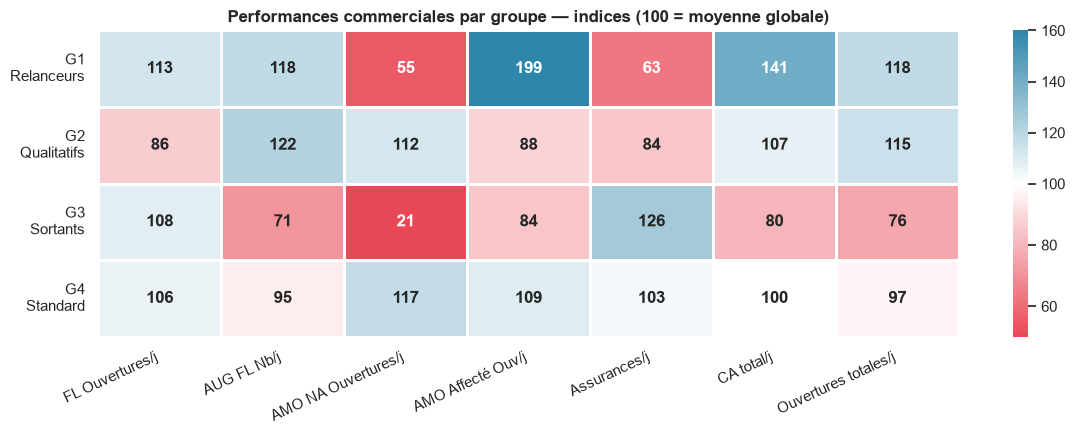

In [35]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ip = indices_perf.set_axis(LABELS_PERF, axis=1)
ip.index = ["G1\nRelanceurs", "G2\nQualitatifs", "G3\nSortants", "G4\nStandard"]
sns.heatmap(ip, annot=True, fmt=".0f", cmap=CMAP_DIV, norm=TwoSlopeNorm(100, 50, 160),
            linewidths=.8, annot_kws={"fontweight": "bold"}, ax=ax)
ax.set_title("Performances commerciales par groupe — indices (100 = moyenne globale)")
ax.set_xlabel(""); ax.set_ylabel(""); plt.xticks(rotation=25, ha="right"); plt.yticks(rotation=0)
montre()

## 7.3 Tests statistiques : Kruskal-Wallis et post-hoc de Dunn

Les ventes sont très asymétriques et la normalité est rejetée dans plusieurs groupes : on utilise le **test de Kruskal-Wallis**, non paramétrique, plutôt qu'une ANOVA ; les comparaisons deux à deux se font par **test de Dunn** avec correction de Bonferroni (implémenté ici avec correction des ex-aequo).

In [36]:
lignes = []
for var, lbl in zip(VARS_PERF, LABELS_PERF):
    h, p = stats.kruskal(*[g.to_numpy() for _, g in df_perf.groupby("groupe")[var]])
    lignes.append({"Indicateur": lbl, "Chi²": h, "ddl": df_perf["groupe"].nunique() - 1,
                   "p-valeur": p, "Significativité": etoiles(p)})
tests_kw = pd.DataFrame(lignes)
tab(tests_kw, "Kruskal-Wallis — comparaison des performances entre groupes", precision=4)

Indicateur,Chi²,ddl,p-valeur,Significativité
FL Ouvertures/j,55.0985,3,0.0000,***
AUG FL Nb/j,168.0117,3,0.0000,***
AMO NA Ouvertures/j,40.1062,3,0.0000,***
AMO Affecté Ouv/j,39.5940,3,0.0000,***
Assurances/j,83.8886,3,0.0000,***
CA total/j,44.5550,3,0.0000,***
Ouvertures totales/j,114.5475,3,0.0000,***


In [37]:
from itertools import combinations


def dunn_bonferroni(df, var, grp):
    """Test de Dunn (1964) avec correction des ex-aequo et ajustement de Bonferroni."""
    d = df[[var, grp]].dropna()
    N = len(d)
    d = d.assign(rang=stats.rankdata(d[var]))
    _, cnt = np.unique(d[var], return_counts=True)
    sigma2 = N * (N + 1) / 12 - (cnt ** 3 - cnt).sum() / (12 * (N - 1))
    r = d.groupby(grp)["rang"].agg(["mean", "size"])
    paires = list(combinations(r.index, 2))
    out = []
    for a, b in paires:
        z = (r.loc[a, "mean"] - r.loc[b, "mean"]) / np.sqrt(sigma2 * (1 / r.loc[a, "size"] + 1 / r.loc[b, "size"]))
        p_adj = min(1.0, 2 * stats.norm.sf(abs(z)) * len(paires))
        out.append({"group1": a, "group2": b, "statistic": z, "p.adj": p_adj, "p.adj.signif": etoiles(p_adj)})
    return pd.DataFrame(out)


for var, lbl, p in zip(VARS_PERF, LABELS_PERF, tests_kw["p-valeur"]):
    if p < .05:
        tab(dunn_bonferroni(df_perf, var, "groupe"), f"Dunn (Bonferroni) — {lbl}", precision=4)

group1,group2,statistic,p.adj,p.adj.signif
1,2,1.5515,0.7247,ns
1,3,-0.2256,1.0000,ns
1,4,-0.3480,1.0000,ns
2,3,-4.8929,0.0000,***
2,4,-7.1773,0.0000,***
3,4,-0.3356,1.0000,ns


group1,group2,statistic,p.adj,p.adj.signif
1,2,-0.2959,1.0000,ns
1,3,4.1759,0.0002,***
1,4,1.8874,0.3546,ns
2,3,12.5393,0.0000,***
2,4,8.2033,0.0000,***
3,4,-7.0422,0.0000,***


group1,group2,statistic,p.adj,p.adj.signif
1,2,-1.8093,0.4224,ns
1,3,0.0163,1.0000,ns
1,4,-2.0564,0.2385,ns
2,3,5.0129,0.0000,***
2,4,-0.8704,1.0000,ns
3,4,-6.0333,0.0000,***


group1,group2,statistic,p.adj,p.adj.signif
1,2,-0.5154,1.0000,ns
1,3,-0.0722,1.0000,ns
1,4,-1.8199,0.4126,ns
2,3,1.2121,1.0000,ns
2,4,-4.8798,0.0000,***
3,4,-5.0795,0.0000,***


group1,group2,statistic,p.adj,p.adj.signif
1,2,-1.1414,1.0000,ns
1,3,-4.2185,0.0001,***
1,4,-2.5493,0.0648,ns
2,3,-8.7128,0.0000,***
2,4,-5.2479,0.0000,***
3,4,5.2437,0.0000,***


group1,group2,statistic,p.adj,p.adj.signif
1,2,-0.0348,1.0000,ns
1,3,2.2181,0.1593,ns
1,4,0.2250,1.0000,ns
2,3,6.3245,0.0000,***
2,4,0.9762,1.0000,ns
3,4,-6.0033,0.0000,***


group1,group2,statistic,p.adj,p.adj.signif
1,2,-0.1102,1.0000,ns
1,3,3.6545,0.0015,**
1,4,1.4168,0.9392,ns
2,3,10.5653,0.0000,***
2,4,5.7343,0.0000,***
3,4,-6.8467,0.0000,***


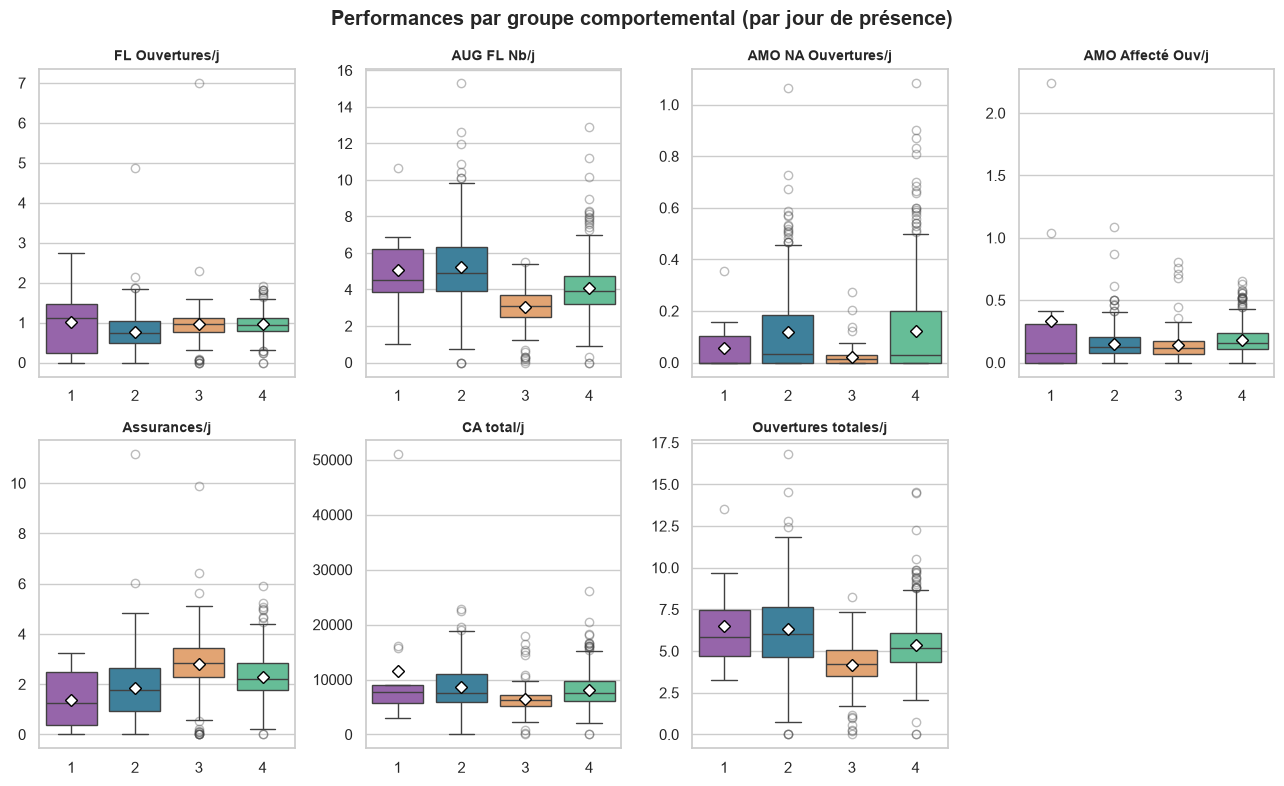

In [38]:
fig, axes = plt.subplots(2, 4, figsize=(13, 8))
for ax, var, lbl in zip(axes.ravel(), VARS_PERF, LABELS_PERF):
    sns.boxplot(data=df_perf, x="groupe", y=var, hue="groupe", palette=PALETTE, legend=False, showmeans=True,
                meanprops=dict(marker="D", mfc="white", mec="black"), flierprops=dict(alpha=.35), ax=ax)
    ax.set_title(lbl, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Performances par groupe comportemental (par jour de présence)", fontweight="bold")
montre()

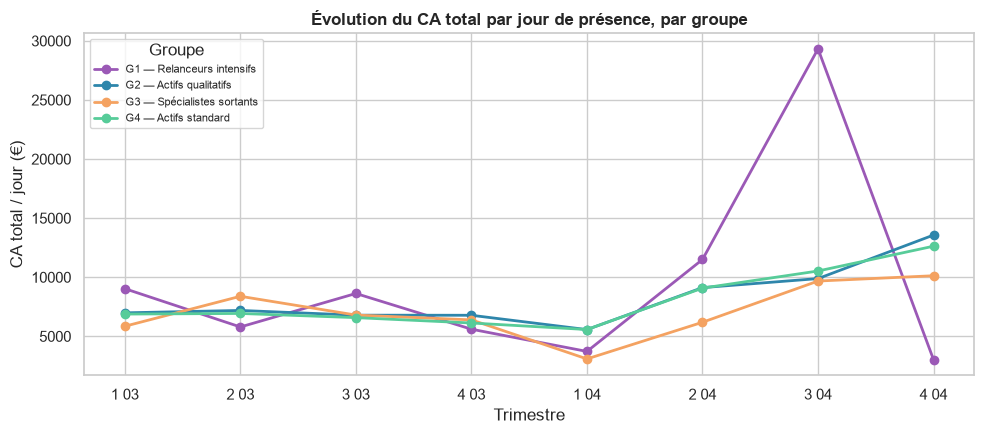

In [39]:
evol = df_perf.groupby(["trimestre", "groupe"], observed=True)["ca_total_j"].mean().unstack("groupe")
fig, ax = plt.subplots(figsize=(10, 4.5))
for g in GROUPES:
    ax.plot(evol.index.astype(str), evol[g], marker="o", lw=2, color=PALETTE[g], label=NOMS_GROUPES[g])
ax.set_xlabel("Trimestre"); ax.set_ylabel("CA total / jour (€)"); ax.legend(title="Groupe", fontsize=8)
ax.set_title("Évolution du CA total par jour de présence, par groupe")
montre()

In [40]:
(df_perf.assign(Groupe=df_perf["groupe"].map(NOMS_GROUPES), Métier=df_perf["metier"])
 .groupby(["Groupe", "Métier"])
 .agg(N=("ca_total_j", "size"), **{"FL ouv/j": ("fl_ouv_j", "mean"), "Assur/j": ("assur_j", "mean"),
                                    "CA total/j": ("ca_total_j", "mean"), "Ouv tot/j": ("ouv_total_j", "mean")})
 .reset_index().pipe(tab, "Performances par groupe et par métier (HML vs NHML)"))

Groupe,Métier,N,FL ouv/j,Assur/j,CA total/j,Ouv tot/j
G1 — Relanceurs intensifs,HML,3,1.763,2.564,25201.851,6.792
G1 — Relanceurs intensifs,NHML,10,0.800,1.037,7344.154,6.393
G2 — Actifs qualitatifs,HML,59,1.101,2.421,10906.644,6.945
G2 — Actifs qualitatifs,NHML,229,0.690,1.710,8125.619,6.129
G3 — Spécialistes sortants,HML,62,1.043,2.798,6867.053,4.517
G3 — Spécialistes sortants,NHML,77,0.918,2.813,6228.667,3.916
G4 — Actifs standard,HML,326,1.003,2.305,8390.265,5.280
G4 — Actifs standard,NHML,141,0.849,2.269,7656.829,5.475


**Lecture.** Les quatre groupes diffèrent sur toutes les ventes (Kruskal-Wallis significatif partout). Les **actifs qualitatifs** sont en tête sur les augmentations de réserves (5,3 par jour) ; les **spécialistes sortants** sont derniers sur les augmentations (3,0), le CA et les ouvertures, mais premiers sur l'assurance. Ces chiffres ne figuraient pas dans les rapports rédigés, qui passaient directement au modèle de score.

---
# 8. Mission 2 : modèle de score « bon vendeur » (régression logistique)

> Le découpage apprentissage / test et le bootstrap utilisent le générateur aléatoire de NumPy (graine 42) et non celui de R : les chiffres peuvent différer légèrement de la version R.

## 8.1 Variable cible

On ne modélise pas le nombre brut d'augmentations de réserves acceptées, mais leur **nombre par jour de présence**. Un conseiller est **« bon vendeur »** s'il fait plus d'augmentations par jour que la médiane de ses collègues.

* Une définition **relative** résiste aux variations saisonnières : un bon vendeur reste bon par rapport à ses pairs.
* Le seuil médian donne deux classes **équilibrées**, ce qui convient bien à une régression logistique.

In [41]:
perf_cible = df_perf.assign(trimestre=df_perf["trimestre"].astype(str))[["code_op", "trimestre", "aug_fl_nb_j"]]
df_m2 = (df_lda[["code_op", "trimestre", "metier", "groupe", *VARS_W]]
         .merge(perf_cible, on=["code_op", "trimestre"], how="inner").reset_index(drop=True))

df_m2["bon_vendeur"] = (df_m2["aug_fl_nb_j"] > df_m2["aug_fl_nb_j"].median()).astype(int)
print("Observations :", len(df_m2), "| Part de bons vendeurs :", round(df_m2["bon_vendeur"].mean() * 100, 1), "%")

Observations : 907 | Part de bons vendeurs : 49.9 %


## 8.2 Analyse bivariée : quelles pratiques sont associées à la performance ?

Mann-Whitney (comparaison des rangs, robuste à la non-normalité) avec taille d'effet *r* = |Z| / √N (seuils : 0,10 faible, 0,30 modéré, 0,50 fort), puis V de Cramér sur les variables discrétisées en terciles (Bas / Moyen / Élevé), avec intervalle de confiance bootstrap à 95 % (500 réplications).

In [42]:
def mann_whitney(x, y):
    """p-valeur (approximation normale, correction de continuité) et taille d'effet r = |Z| / √N."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    p = stats.mannwhitneyu(x, y, method="asymptotic", use_continuity=True).pvalue
    n1, n2 = len(x), len(y); N = n1 + n2
    U = stats.mannwhitneyu(x, y, method="asymptotic", use_continuity=False).statistic
    _, cnt = np.unique(np.concatenate([x, y]), return_counts=True)
    var = n1 * n2 / 12 * ((N + 1) - (cnt ** 3 - cnt).sum() / (N * (N - 1)))
    return p, abs((U - n1 * n2 / 2) / np.sqrt(var)) / np.sqrt(N)


lignes = []
for var, lbl in zip(VARS_W, LABELS_VARS):
    bon, mauvais = df_m2.loc[df_m2.bon_vendeur == 1, var], df_m2.loc[df_m2.bon_vendeur == 0, var]
    p, r = mann_whitney(mauvais, bon)
    lignes.append({"Variable": lbl, "Médiane mauvais": mauvais.median(), "Médiane bon": bon.median(),
                   "p-valeur": p, "r": r})
mw = pd.DataFrame(lignes).sort_values("r", ascending=False)
tab(mw, "Mann-Whitney — bons vs mauvais vendeurs")

Variable,Médiane mauvais,Médiane bon,p-valeur,r
Appels pris/j,86.243,105.354,0.000,0.404
Conv ent/j,186.083,241.003,0.000,0.394
Appels prés/j,93.455,112.385,0.000,0.385
App pris/h,17.614,20.186,0.000,0.349
Part conv/dispo,0.758,0.819,0.000,0.343
Part sort/conv,0.107,0.070,0.000,0.339
Conv tot/j,225.648,257.970,0.000,0.312
Conv sort/j,22.237,18.001,0.000,0.232
Retrait/j,52.277,65.083,0.000,0.199
Dispo/j,303.303,317.184,0.000,0.156


In [43]:
def terciles(x):
    return pd.cut(x, np.quantile(x, [0, 1 / 3, 2 / 3, 1]), labels=["Bas", "Moyen", "Élevé"], include_lowest=True)


def cramer_v(x, y):
    """V de Cramér d'un tableau 3 × 2 (x : codes 0-2 des terciles, y : 0/1), sans correction de continuité."""
    t = np.bincount(x * 2 + y, minlength=6).reshape(3, 2).astype(float)
    attendu = np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        chi2 = np.nansum((t - attendu) ** 2 / attendu)
    return np.sqrt(chi2 / (t.sum() * (min(t.shape) - 1)))


rng = np.random.default_rng(42)
y_bv = df_m2["bon_vendeur"].to_numpy()
n = len(y_bv)
lignes = []
for var, lbl in zip(VARS_W, LABELS_VARS):
    x = terciles(df_m2[var]).cat.codes.to_numpy().astype(int)
    boot = np.array([cramer_v(x[s], y_bv[s]) for s in rng.integers(0, n, size=(500, n))])
    lignes.append({"Variable": lbl, "V": cramer_v(x, y_bv),
                   "IC 2,5 %": np.quantile(boot, .025), "IC 97,5 %": np.quantile(boot, .975)})
vc = pd.DataFrame(lignes).sort_values("V", ascending=False)
tab(vc, "V de Cramér — association avec « bon vendeur » (terciles)")

Variable,V,"IC 2,5 %","IC 97,5 %"
Conv ent/j,0.393,0.341,0.448
Appels pris/j,0.379,0.321,0.438
Appels prés/j,0.346,0.291,0.405
App pris/h,0.339,0.272,0.401
Part sort/conv,0.319,0.259,0.386
Part conv/dispo,0.317,0.257,0.374
Conv tot/j,0.299,0.234,0.360
Conv sort/j,0.223,0.160,0.297
Retrait/j,0.195,0.142,0.263
Dispo/j,0.147,0.088,0.214


**Lecture.**

* Les **bons vendeurs** prennent plus d'appels par jour (médiane de 105 contre 86), passent une plus grande part de leur temps disponible en conversation (0,82 contre 0,76) et prennent plus d'appels par heure.
* Leur **part d'appels sortants** est plus faible (7 % contre 11 %). Une piste d'explication : une augmentation de réserve se vend mieux quand c'est le client qui appelle, avec un besoin, que lors d'une relance à froid.
* **V de Cramér** : les volumes entrants ont les liens les plus forts (conversation entrante 0,39, appels pris 0,38), puis viennent les appels présentés, les appels par heure, la part de sortants et la part de conversation (0,32 à 0,35). Le **TMC entrants** a le lien le plus faible (0,07) : la durée des entretiens ne distingue pas les bons vendeurs.

## 8.3 Multicolinéarité : un représentant par bloc

La matrice de Spearman montre deux blocs de variables presque redondantes : le volume entrant (appels présentés, appels pris, disponibilité, conversation totale) et l'activité sortante (conversation sortante et part de sortants). On garde un représentant par bloc. Parmi les 8 candidates, deux VIF restent au-dessus de 10 (TMC entrants et appels pris par heure) : le TMC n'entre pas dans le modèle, et dans le modèle final à 4 variables tous les VIF restent sous 2.

### Régression logistique : implémentation (IRLS)

La régression logistique est estimée par moindres carrés itérativement repondérés (IRLS), l'algorithme de `glm(family = binomial)` en R. La matrice de variance-covariance des coefficients donne les erreurs standards, les intervalles de confiance et le VIF.

In [44]:
class Logit:
    """Régression logistique par IRLS (équivalent de glm(family = binomial) en R)."""

    def __init__(self, X, y):
        self.cols = list(X.columns)
        self.noms = ["(Intercept)"] + self.cols
        A = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
        y = np.asarray(y, dtype=float)
        beta = np.zeros(A.shape[1])
        for _ in range(100):
            p = expit(A @ beta)
            w = p * (1 - p)
            pas = np.linalg.solve(A.T @ (A * w[:, None]), A.T @ (y - p))
            beta = beta + pas
            if np.max(np.abs(pas)) < 1e-10:
                break
        p = expit(A @ beta)
        w = p * (1 - p)
        eps = 1e-15
        self.n, self.k = len(y), A.shape[1]
        self.beta = pd.Series(beta, index=self.noms)
        self.cov = pd.DataFrame(np.linalg.inv(A.T @ (A * w[:, None])), index=self.noms, columns=self.noms)
        self.se = pd.Series(np.sqrt(np.diag(self.cov)), index=self.noms)
        self.fitted = p
        self.llf = float(np.sum(y * np.log(np.clip(p, eps, 1)) + (1 - y) * np.log(np.clip(1 - p, eps, 1))))
        pbar = y.mean()
        self.llnull = float(self.n * (pbar * np.log(pbar) + (1 - pbar) * np.log(1 - pbar)))
        self.aic = -2 * self.llf + 2 * self.k
        self.bic = -2 * self.llf + self.k * np.log(self.n)

    def predict(self, X):
        A = np.column_stack([np.ones(len(X)), X[self.cols].to_numpy(dtype=float)])
        return expit(A @ self.beta.to_numpy())

    def resume(self):
        z = self.beta / self.se
        return pd.DataFrame({"Estimate": self.beta, "Std. Error": self.se, "z value": z,
                             "Pr(>|z|)": 2 * stats.norm.sf(np.abs(z))})

    def vif(self):
        """VIF généralisé (car::vif) : diagonale de l'inverse de la matrice de corrélation des estimations."""
        C = self.cov.iloc[1:, 1:]
        d = np.sqrt(np.diag(C))
        return pd.Series(np.diag(np.linalg.inv(C.to_numpy() / np.outer(d, d))), index=C.index)


VARS_CAND = ["appels_pris_j_w", "appels_pris_h_w", "part_conv_dispo_w", "part_sortant_conv_w",
             "appels_sortants_j_w", "taux_decroche_w", "retrait_min_j_w", "tmc_entrants_w"]

# Découpage apprentissage / test (80 / 20, graine fixe) AVANT toute estimation
rng = np.random.default_rng(42)
perm = rng.permutation(len(df_m2))
n_train = int(np.floor(.8 * len(df_m2)))
train, test = df_m2.iloc[perm[:n_train]].copy(), df_m2.iloc[perm[n_train:]].copy()

# Standardisation calculée sur l'apprentissage UNIQUEMENT, puis appliquée au test
mu, sdv = train[VARS_W].mean(), train[VARS_W].std()


def standardise(d):
    d = d.copy()
    d[VARS_W] = (d[VARS_W] - mu) / sdv
    return d


train_s, test_s, all_s = standardise(train), standardise(test), standardise(df_m2)

vif_cand = Logit(train_s[VARS_CAND], train_s["bon_vendeur"]).vif()
tab(vif_cand.rename("VIF").rename_axis("Variable").reset_index(), "VIF des 8 variables candidates (seuil : 10)", precision=2)

Variable,VIF
appels_pris_j_w,1.71
appels_pris_h_w,12.33
part_conv_dispo_w,5.32
part_sortant_conv_w,6.92
appels_sortants_j_w,1.54
taux_decroche_w,1.25
retrait_min_j_w,1.69
tmc_entrants_w,24.56


## 8.4 Ordre d'entrée des variables et construction séquentielle

Plutôt qu'un *stepwise* automatique (sur-ajustement sur l'échantillon d'apprentissage, sensibilité à l'ordre initial), l'ordre d'entrée est défini **a priori** d'après la corrélation de Spearman de chaque variable avec la cible : transparent, reproductible, justifiable. Le modèle est construit une variable à la fois et évalué à chaque étape sur l'**échantillon test indépendant** (20 %).

In [45]:
ORDRE_ENTREE = ["appels_pris_j_w", "appels_pris_h_w", "part_conv_dispo_w",
                "part_sortant_conv_w", "appels_sortants_j_w", "taux_decroche_w"]

cor_cible = pd.Series({v_: stats.spearmanr(train[v_], train["bon_vendeur"])[0] for v_ in VARS_CAND})
(cor_cible.rename("Spearman avec la cible").rename_axis("Variable").reset_index()
 .sort_values("Spearman avec la cible", key=np.abs, ascending=False)
 .pipe(tab, "Corrélation de Spearman avec la cible (échantillon d'apprentissage)"))

lignes = []
for k in range(1, 7):
    m = Logit(train_s[ORDRE_ENTREE[:k]], train_s["bon_vendeur"])
    lignes.append({"k": k, "Variable ajoutée": ORDRE_ENTREE[k - 1],
                   "AUC test": roc_auc_score(test_s["bon_vendeur"], m.predict(test_s)),
                   "AIC": round(m.aic), "BIC": round(m.bic)})
seq_tab = pd.DataFrame(lignes)
seq_tab["Δ AUC"] = seq_tab["AUC test"].diff()
tab(seq_tab, "Construction séquentielle du modèle", precision=4)

m4 = Logit(train_s[ORDRE_ENTREE[:4]], train_s["bon_vendeur"])
m6 = Logit(train_s[ORDRE_ENTREE[:6]], train_s["bon_vendeur"])
lrt = 2 * (m6.llf - m4.llf)
print(f"Test du rapport de vraisemblance M4 vs M6 : chi² = {lrt:.3f}, ddl = 2, p = {stats.chi2.sf(lrt, 2):.3f}")

Variable,Spearman avec la cible
appels_pris_j_w,0.392
part_conv_dispo_w,0.356
appels_pris_h_w,0.348
part_sortant_conv_w,-0.338
retrait_min_j_w,0.214
appels_sortants_j_w,-0.157
taux_decroche_w,0.113
tmc_entrants_w,0.041


k,Variable ajoutée,AUC test,AIC,BIC,Δ AUC
1,appels_pris_j_w,0.7662,883,892,nan
2,appels_pris_h_w,0.7743,869,882,0.0082
3,part_conv_dispo_w,0.8136,781,800,0.0392
4,part_sortant_conv_w,0.8175,774,797,0.0040
5,appels_sortants_j_w,0.8168,776,804,-0.0007
6,taux_decroche_w,0.8179,775,807,0.0011


Test du rapport de vraisemblance M4 vs M6 : chi² = 3.389, ddl = 2, p = 0.184


**Choix du modèle M4.** Jusqu'à la troisième variable, chaque ajout fait gagner de l'AUC (0,766 puis 0,774 puis 0,814). La quatrième (part de sortants) apporte encore 0,004 et fait baisser l'AIC et le BIC. Ensuite, plus rien : AUC stable autour de 0,817, BIC qui remonte (797 puis 804 puis 807), et le test du rapport de vraisemblance entre M4 et M6 ne rejette pas l'idée que les deux variables de plus n'apportent rien (p = 0,18). On garde donc 4 variables.

## 8.5 Le modèle final M4

Les variables étant standardisées, les coefficients sont **directement comparables** : chacun mesure l'effet d'une hausse d'un écart-type.

In [46]:
res = m4.resume()
tab(res.rename_axis("").reset_index(), "Modèle M4 — coefficients (variables standardisées)", precision=4)
print(f"Déviance nulle : {-2 * m4.llnull:.1f} sur {m4.n - 1} ddl | Déviance résiduelle : {-2 * m4.llf:.1f} "
      f"sur {m4.n - m4.k} ddl | AIC : {m4.aic:.1f}")

zc = stats.norm.ppf(.975)
b, se = m4.beta.iloc[1:], m4.se.iloc[1:]
or_tab = pd.DataFrame({"Variable": b.index, "β std.": b.values, "OR": np.exp(b.values),
                       "IC 2,5 %": np.exp(b.values - zc * se.values), "IC 97,5 %": np.exp(b.values + zc * se.values)})
tab(or_tab, "Odds ratios (IC de Wald)", precision=3)


def hosmer_lemeshow(y, p, g=10):
    """Test de Hosmer-Lemeshow (g groupes de risque, ddl = g − 2), comme ResourceSelection::hoslem.test."""
    bornes = np.unique(np.quantile(p, np.linspace(0, 1, g + 1)))
    classe = pd.cut(p, bornes, include_lowest=True)
    d = pd.DataFrame({"y": y, "p": p, "c": classe}).groupby("c", observed=True).agg(n=("y", "size"), o1=("y", "sum"), e1=("p", "sum"))
    stat = (((d.o1 - d.e1) ** 2 / d.e1) + (((d.n - d.o1) - (d.n - d.e1)) ** 2 / (d.n - d.e1))).sum()
    ddl = len(d) - 2
    return stat, ddl, stats.chi2.sf(stat, ddl)


mcfadden = 1 - m4.llf / m4.llnull
p_test = m4.predict(test_s)
auc_train = roc_auc_score(train_s["bon_vendeur"], m4.fitted)
auc_test = roc_auc_score(test_s["bon_vendeur"], p_test)
hl = hosmer_lemeshow(train_s["bon_vendeur"].to_numpy(), m4.fitted)
print(f"McFadden R² : {mcfadden:.3f} | AUC train : {auc_train:.3f} | AUC test : {auc_test:.3f}")
print(f"Hosmer-Lemeshow : chi² = {hl[0]:.2f}, ddl = {hl[1]}, p = {hl[2]:.3f}")

,Estimate,Std. Error,z value,Pr(>|z|)
(Intercept),0.0008,0.0902,0.0092,0.9927
appels_pris_j_w,0.7688,0.1283,5.9899,0.0000
appels_pris_h_w,0.4824,0.1217,3.9625,0.0001
part_conv_dispo_w,0.8971,0.1215,7.3839,0.0000
part_sortant_conv_w,-0.3472,0.1245,-2.7884,0.0053


Déviance nulle : 1005.0 sur 724 ddl | Déviance résiduelle : 764.5 sur 720 ddl | AIC : 774.5


Variable,β std.,OR,"IC 2,5 %","IC 97,5 %"
appels_pris_j_w,0.769,2.157,1.677,2.774
appels_pris_h_w,0.482,1.620,1.276,2.057
part_conv_dispo_w,0.897,2.452,1.933,3.112
part_sortant_conv_w,-0.347,0.707,0.554,0.902


McFadden R² : 0.239 | AUC train : 0.812 | AUC test : 0.818
Hosmer-Lemeshow : chi² = 10.41, ddl = 8, p = 0.237


**Le score.**

$$\text{logit}\,P(\text{bon vendeur}) = 0{,}001 + 0{,}769\,\text{Appels pris/j} + 0{,}482\,\text{Appels pris/h} + 0{,}897\,\text{Part conv./dispo} - 0{,}347\,\text{Part sort./conv}$$

| Indicateur | Valeur | Lecture |
|---|---|---|
| R² de McFadden | 0,239 | Bon ajustement pour ce type de modèle |
| AUC test (20 %) | 0,818 | Bon pouvoir de discrimination |
| AUC apprentissage (80 %) | 0,812 | Très proche du test : pas de sur-apprentissage |
| Hosmer-Lemeshow | p = 0,24 | Probabilités bien calibrées |

**Les odds ratios** (effet d'une hausse d'un écart-type) :

* **Part du temps disponible en conversation : 2,45.** C'est le levier le plus fort : parler à des clients plutôt que rester en attente ou en retrait.
* **Appels pris par jour : 2,16.** Les augmentations de réserves se proposent pendant les appels entrants : plus on en traite, plus on a d'occasions.
* **Appels pris par heure : 1,62.** Enchaîner les appels de façon fluide compte aussi.
* **Part des sortants dans la conversation : 0,71.** Seule variable défavorable : environ 29 % de chances en moins. Pour *ce produit*, la vente marche mieux sur un appel entrant.

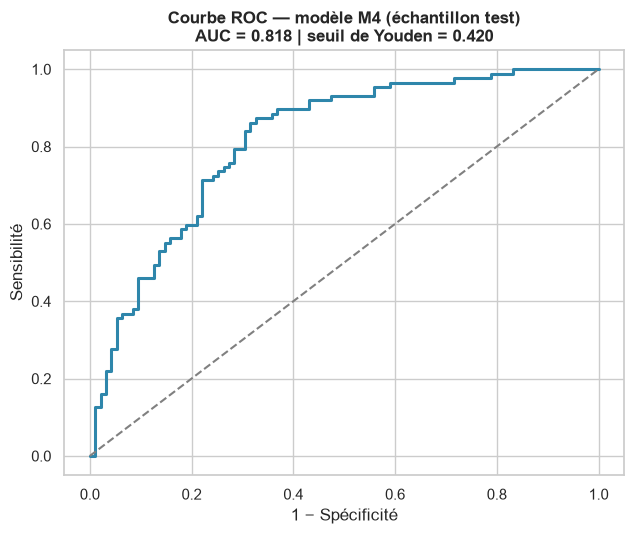

In [47]:
y_test = test_s["bon_vendeur"].to_numpy()
fpr, tpr, seuils_roc = roc_curve(y_test, p_test)
seuil_youden = float(seuils_roc[np.argmax(tpr - fpr)])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr, tpr, color="#2E86AB", lw=2.2)
ax.plot([0, 1], [0, 1], ls="--", color="grey")
ax.set_xlabel("1 − Spécificité"); ax.set_ylabel("Sensibilité")
ax.set_title(f"Courbe ROC — modèle M4 (échantillon test)\nAUC = {auc_test:.3f} | seuil de Youden = {seuil_youden:.3f}")
montre("courbe_roc")

In [48]:
def metriques(seuil):
    pred = (p_test >= seuil).astype(int)
    tp = int(((pred == 1) & (y_test == 1)).sum()); tn = int(((pred == 0) & (y_test == 0)).sum())
    fp = int(((pred == 1) & (y_test == 0)).sum()); fn = int(((pred == 0) & (y_test == 1)).sum())
    return {"Seuil": seuil, "Accuracy": (tp + tn) / len(y_test), "Sensibilité": tp / (tp + fn),
            "Spécificité": tn / (tn + fp), "VPP": tp / (tp + fp) if tp + fp else np.nan,
            "VPN": tn / (tn + fn) if tn + fn else np.nan, "F1": 2 * tp / (2 * tp + fp + fn)}


tab(pd.DataFrame([metriques(s) for s in (.5, seuil_youden, .6)]),
    "Métriques de classification selon le seuil (échantillon test)")

Seuil,Accuracy,Sensibilité,Spécificité,VPP,VPN,F1
0.500,0.742,0.747,0.737,0.722,0.761,0.734
0.420,0.769,0.874,0.674,0.710,0.853,0.784
0.600,0.703,0.586,0.811,0.739,0.681,0.654


**Lecture.** Au seuil de Youden (0,42), sur 182 observations de test, le modèle repère **87 % des bons vendeurs** (76 sur 87) et reconnaît **67 % des autres** (64 sur 95) ; 77 % des observations sont bien classées. Quand il annonce « bon vendeur », il a raison 71 fois sur 100, contre 48 % en choisissant au hasard. Au seuil de 0,5, les deux erreurs s'équilibrent (sensibilité 75 %, spécificité 74 %). Le choix du seuil dépend de l'usage : seuil bas pour ne rater personne lors d'une action de formation, seuil haut si les places sont limitées.

### Analyse par décile et courbe de lift

*Si le responsable ne peut accompagner en priorité que 20 % des conseillers, lesquels choisir ?*

In [49]:
n_t = len(p_test)
rang = stats.rankdata(p_test, method="ordinal")
decile = np.floor(10 * (rang - 1) / n_t).astype(int) + 1          # équivalent de dplyr::ntile(p, 10)

lift_df = (pd.DataFrame({"décile": decile, "y": y_test}).groupby("décile")
           .agg(N=("y", "size"), **{"% bons vendeurs": ("y", lambda s: s.mean() * 100)}).reset_index())
lift_df["Lift"] = lift_df["% bons vendeurs"] / (y_test.mean() * 100)
tab(lift_df, "Analyse par décile de score (décile 10 = scores les plus élevés)", precision=2)

décile,N,% bons vendeurs,Lift
1,19,5.26,0.11
2,18,11.11,0.23
3,18,16.67,0.35
4,18,27.78,0.58
5,18,61.11,1.28
6,19,68.42,1.43
7,18,55.56,1.16
8,18,61.11,1.28
9,18,88.89,1.86
10,18,83.33,1.74


**Lecture.** Dans les deux déciles de score les plus élevés, 86 % des observations sont de vrais bons vendeurs, soit 1,8 fois la proportion de la base (lift de 1,74 à 1,86). Dans les deux déciles les plus bas, ils ne sont que 5 % et 11 %. En ciblant les 20 % de scores les plus hauts, on retrouve 36 % de tous les bons vendeurs.

---
# 9. Mission 2 — Croisement : score logistique × groupes comportementaux

Les deux analyses ont été menées de manière **entièrement indépendante** : la classification n'utilise que la téléphonie, sans donnée de vente ; le modèle logistique n'utilise ni l'appartenance aux groupes ni les variables qui les définissent directement. Si elles captent les mêmes phénomènes sous-jacents, leurs résultats doivent converger : c'est un test de **cohérence externe**.

In [50]:
df_m2["score"] = m4.predict(all_s)

cro = (df_m2.groupby("groupe")
       .agg(**{"Effectif total": ("bon_vendeur", "size"), "Bons vendeurs": ("bon_vendeur", "sum"),
               "% bons vendeurs": ("bon_vendeur", lambda s: s.mean() * 100),
               "Score moyen": ("score", "mean"), "_sd": ("score", "std")}))
marge = 1.96 * cro["_sd"] / np.sqrt(cro["Effectif total"])
cro["IC 95 % bas"], cro["IC 95 % haut"] = cro["Score moyen"] - marge, cro["Score moyen"] + marge
cro["Rang"] = cro["% bons vendeurs"].rank(ascending=False).astype(int)
cro.insert(0, "Groupe", cro.index.map(NOMS_GROUPES))
tab(cro.drop(columns="_sd").reset_index(drop=True),
    "Taux de bons vendeurs et score moyen par groupe comportemental")

Groupe,Effectif total,Bons vendeurs,% bons vendeurs,Score moyen,IC 95 % bas,IC 95 % haut,Rang
G1 — Relanceurs intensifs,13,9,69.231,0.899,0.779,1.020,2
G2 — Actifs qualitatifs,288,202,70.139,0.691,0.667,0.714,1
G3 — Spécialistes sortants,139,24,17.266,0.172,0.151,0.194,4
G4 — Actifs standard,467,218,46.681,0.473,0.453,0.492,3


## 9.1 Tables pour le tableau de bord Power BI

Les résultats sont exportés en CSV (séparateur `;`, décimale `,`) dans `sorties/`. Le rapport Power BI `powerbi/cofitypotel.pbix` lit ces fichiers.

In [51]:
# Tables pour Power BI (une ligne par conseiller et par trimestre, codes anonymisés)
faits = (df_m2[["code_op", "trimestre", "metier", "groupe", "bon_vendeur", "score", "aug_fl_nb_j"] + VARS_W]
         .merge(df_perf[["code_op", "trimestre", "fl_ouv_j", "amo_na_ouv_j", "amo_af_ouv_j", "assur_j",
                         "ca_total_j", "ouv_total_j", "nb_jours_tot"]].assign(trimestre=lambda d: d["trimestre"].astype(str)),
                on=["code_op", "trimestre"], how="left"))
faits["nom_groupe"] = faits["groupe"].map(NOMS_GROUPES)
faits["annee"] = "20" + faits["trimestre"].str[-2:]
faits["num_trimestre"] = faits["trimestre"].str[0].astype(int)
faits["periode"] = faits["annee"] + "-T" + faits["num_trimestre"].astype(str)
faits["echantillon"] = np.where(faits.index.isin(test.index), "test", "apprentissage")
faits.to_csv(DOSSIER_SORTIES / "conseillers_trimestres.csv", index=False, sep=";", decimal=",", encoding="utf-8")

groupes = pd.DataFrame({"groupe": GROUPES, "nom_groupe": [NOMS_GROUPES[g] for g in GROUPES],
                        "couleur": [PALETTE[g] for g in GROUPES]})
groupes.to_csv(DOSSIER_SORTIES / "groupes.csv", index=False, sep=";", encoding="utf-8")

indices.rename(index=NOMS_GROUPES).reset_index().melt(id_vars="Groupe", var_name="indicateur", value_name="indice") \
    .to_csv(DOSSIER_SORTIES / "indices_groupes.csv", index=False, sep=";", decimal=",", encoding="utf-8")

(mat_trans.rename(index=lambda g: f"G{g}", columns=lambda g: f"G{g}").stack().rename("transitions")
 .reset_index().rename(columns={"Départ": "depart", "Arrivée": "arrivee"})
 .to_csv(DOSSIER_SORTIES / "migrations.csv", index=False, sep=";", encoding="utf-8"))

or_tab.to_csv(DOSSIER_SORTIES / "odds_ratios.csv", index=False, sep=";", decimal=",", encoding="utf-8")
print("Tables écrites dans sorties/ :", sorted(p.name for p in DOSSIER_SORTIES.glob("*.csv")))

Tables écrites dans sorties/ : ['conseillers_trimestres.csv', 'groupes.csv', 'indices_groupes.csv', 'migrations.csv', 'odds_ratios.csv']


**Lecture.**

| Groupe | Effectif | Bons vendeurs | Score moyen | Rang |
|---|---|---|---|---|
| G2 : actifs qualitatifs | 288 | 70,1 % | 0,69 | 1er |
| G1 : relanceurs intensifs | 13 | 69,2 % | 0,90 | 2e (effectif trop faible) |
| G4 : actifs standard | 467 | 46,7 % | 0,47 | 3e |
| G3 : spécialistes sortants | 139 | 17,3 % | 0,17 | 4e |

* **Les spécialistes sortants sont les moins performants dans les deux analyses** : 17 % de bons vendeurs et un score moyen de 0,17. Leur trait principal, une forte part d'appels sortants, est justement la seule variable défavorable du modèle.
* **Les actifs qualitatifs vendent le mieux** : 70 % de bons vendeurs, et le score le retrouve (0,69). Ils combinent un gros volume d'appels entrants et très peu de relances, exactement ce que le modèle valorise.
* **Les actifs standard sont au milieu** (47 %), ce qui colle à leur profil proche de la moyenne.
* **Ce qui change par rapport au rapport rédigé.** Le tableau de croisement du rapport n°2 classait les relanceurs intensifs premiers avec 264 conseillers, et les actifs qualitatifs troisièmes. Ces effectifs ne correspondaient pas à la typologie de la mission 1 (13 relanceurs). Recalculé sur la même partition que la mission 1, le croisement donne le classement ci-dessus, qui rejoint d'ailleurs la conclusion écrite du rapport n°2.

---
# 10. Préconisations

## 10.1 Utiliser les groupes comme outil de pilotage

* **Ajouter le groupe de chaque conseiller** au tableau de bord trimestriel, à côté de ses ventes.
* **Affecter un nouveau conseiller** à un groupe après un trimestre de données, avec la fonction `predire_groupe()`.
* **Suivre les changements de groupe** plutôt que le groupe d'un seul trimestre : la moitié des conseillers change de groupe d'un trimestre au suivant.

## 10.2 Adapter l'accompagnement

| Groupe | Point fort | Piste de progrès |
|---|---|---|
| G2 : qualitatifs | Volume d'entrants, peu de temps perdu | Servir de référence et partager leurs pratiques |
| G4 : standard | Polyvalence | Pour les HML, mesurer le temps pris par les études en ligne avant de juger le volume |
| G3 : sortants | Culture de la relance | Recentrer sur les appels entrants pour ce produit |
| G1 : relanceurs | Activité très forte | Suivi individuel (13 observations) |

**Recommandation principale.** Orienter la formation en priorité vers les **spécialistes sortants**, pour qu'ils convertissent davantage sur les appels entrants. Pour les augmentations de réserves, la relance sortante intensive n'est pas efficace.

---
# 11. Limites et perspectives

## 11.1 Limites

* Huit trimestres et 251 conseillers, c'est court. Certains conseillers n'apparaissent qu'un ou deux trimestres, et 93 observations ne couvrent qu'un mois dans le trimestre.
* G1 (13 observations) est sous le minimum théorique de l'analyse discriminante.
* Le choix de 4 groupes est un choix d'interprétation : la silhouette est presque la même pour 2, 3 ou 4 groupes.
* La typologie est sensible au traitement du temps de retrait : avec la conversion tronquée de la version d'origine, les effectifs des groupes changent nettement.
* **Corrélation n'est pas causalité** : copier les pratiques d'un groupe performant n'augmentera pas mécaniquement les ventes.
* Le score ne vaut que pour les augmentations de réserves.

## 11.2 Perspectives

* Tester le score sur d'autres produits et sur des données plus récentes.
* Comparer avec une analyse discriminante quadratique et d'autres nombres de groupes.
* Ajouter la charge d'études en ligne des HML au modèle.

---
# 12. Annexes

## 12.1 Glossaire

| Terme | Définition |
|---|---|
| **ACP** | Analyse en Composantes Principales : résume des variables corrélées en quelques axes indépendants. |
| **CAH** | Classification Ascendante Hiérarchique : regroupe pas à pas les observations les plus proches (critère de Ward). |
| **K-means** | Affecte chaque observation au groupe dont le centre est le plus proche, jusqu'à stabilité. |
| **LDA** | Analyse Discriminante Linéaire : combine les variables pour séparer au mieux des groupes connus. |
| **Silhouette** | Qualité d'une classification, de −1 à +1. |
| **LOO** | Validation croisée Leave-One-Out : chaque observation est prédite par un modèle estimé sans elle. |
| **Winsorisation** | Les valeurs sous le 1er percentile ou au-dessus du 99e sont ramenées à ces bornes. |
| **Indice base 100** | Moyenne d'un groupe divisée par la moyenne globale, × 100. |
| **TMC** | Temps moyen de conversation : conversation entrante / appels pris. |
| **HML / NHML** | Habilités / non habilités au montage de crédit en ligne. |
| **VIF** | Mesure de la redondance d'une variable avec les autres (seuil usuel : 10). |
| **AUC** | Probabilité que le modèle donne un meilleur score à un bon vendeur qu'à un autre (0,5 = hasard). |
| **Seuil de Youden** | Seuil qui maximise sensibilité + spécificité. |
| **Lift** | Proportion de bons vendeurs dans une tranche de score, divisée par leur proportion dans la base. |

## 12.2 Reproductibilité

* **Environnement** : Python 3.10 ou plus, bibliothèques listées dans `requirements.txt`.
* **Entrée** : `donnees/Donnees_Cofitypotel.xls` (feuille `Feuil1`, 5 lignes d'en-tête à ignorer).
* **Graines** : `random_state = 42` pour le K-means, `default_rng(42)` pour le bootstrap et le découpage apprentissage / test.
* **Différences avec la version R d'origine** : conversion complète du temps de retrait, générateurs aléatoires différents, K-means de Lloyd au lieu de Hartigan-Wong.

In [52]:
import platform, sklearn, scipy
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} "
      f"| scikit-learn {sklearn.__version__}")

Python 3.12.7 | numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1
